# Face Detection and Recognition System using Deep Learning
### 23ELC364 – Deep Learning Case Study

| | |
|---|---|
| **Dataset** | LFW – Labeled Faces in the Wild (12 people with ≥ 50 photos = 1,560 images; 5,700+ other people used as strangers / new people) |
| **Face detection** | Haar Cascade (Viola–Jones) and YuNet (CNN detector), with crop calibration |
| **Main model** | **MobileNetV2 transfer learning + fine-tuning** |
| **Compared with** | Basic CNN, Improved CNN (BatchNorm + Dropout + Augmentation), VGG16, MobileNetV2 + ArcFace |
| **Framework** | TensorFlow / Keras, OpenCV, scikit-learn; GUI built into the notebook (HTML + JavaScript) |

### Features
| Area | What is included |
|---|---|
| Models | 5 models compared · ablation study (augmentation, class weights, fine-tuning) · repeated with 3 seeds (mean ± std) |
| Evaluation | accuracy, macro F1, confusion matrix, correct / wrong galleries, 95% confidence interval, McNemar significance test |
| Understanding the model | feature maps · Grad-CAM heatmaps · t-SNE map of face embeddings |
| Robustness | test-time augmentation · accuracy under darkness, blur, noise, low resolution, **sunglasses** and **mask** |
| Real-world recognition | "Unknown" stranger rejection · add new people **without retraining** · face verification · official LFW 6,000-pair benchmark |
| Deployment | per-image latency · TensorFlow Lite model (4× smaller) · laptop app (`app.py`) |
| **GUI** | recognize photos · live webcam · **video analysis** · enroll (files or webcam) · verify · attendance with CSV · model report |
| **Memory** | enrolled people and attendance saved to **Google Drive** – recognised again in later sessions, even after retraining · instant launcher (`Launch_GUI.ipynb`) |

**How to run (first time):** `Runtime → Change runtime type → T4 GPU`, then `Runtime → Run all` (≈ 40 min; set `QUICK_MODE = True` in cell 1 for ≈ 15 min).
👉 At the start a **Google Drive pop-up** appears – click **Allow** so the app can remember people. Then you can leave it running.
The GUI opens **inside the notebook** in Section 21 – no external link.

**Every time after that:** open **`Launch_GUI.ipynb`** → Run all → the GUI is ready in ~1 minute, no retraining, and it **remembers everyone you enrolled**.

### Pipeline
```
Photo / webcam / video ─► Face detection ─► crop + resize 160×160 ─► MobileNetV2 ─► 256-number face embedding
                           (Haar / YuNet)                                               │
                                                                 compare with every person in the gallery
                                                                                        │
                                                       Name + similarity   or   "Unknown" (below threshold)
```

In [ ]:
# ============================================================
# 1. IMPORT LIBRARIES AND SETTINGS
# ============================================================

import os
import gc
import json
import time
import shutil
import random
import warnings
import urllib.request
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
from scipy import stats

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.datasets import fetch_lfw_people, get_data_home
from sklearn.model_selection import train_test_split, KFold
from sklearn.utils.class_weight import compute_class_weight
from sklearn.manifold import TSNE
from sklearn.metrics import (confusion_matrix, classification_report, accuracy_score, f1_score,
                             recall_score, roc_curve, roc_auc_score)

QUICK_MODE = True                       # True -> 1 seed instead of 3 (about 15 min instead of 40)
SEED = 42
SEEDS = [42] if QUICK_MODE else [42, 7, 2024]
IMG_SIZE = 160

random.seed(SEED)
np.random.seed(SEED)
keras.utils.set_random_seed(SEED)

# ---- Google Drive: remembers enrolled people, attendance and the trained app between sessions ----
USE_GOOGLE_DRIVE = True                  # a pop-up asks for permission once: click "Allow"
SAVE_DIR = "face_app_bundle"
if USE_GOOGLE_DRIVE:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        SAVE_DIR = "/content/drive/MyDrive/Face_Recognition_Project"
    except Exception as e:
        print("Google Drive not used (files stay in this session only):", e)
os.makedirs(SAVE_DIR, exist_ok=True)
print("App files and enrolled people are saved in:", SAVE_DIR)

# Every figure is also saved in the "figures" folder for the report
os.makedirs("figures", exist_ok=True)
def save_show(name):
    plt.savefig(f"figures/{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

print("TensorFlow version:", tf.__version__)
print("Keras version     :", keras.__version__)
print("OpenCV version    :", cv2.__version__)
print("GPU               :", tf.config.list_physical_devices("GPU"))
print("Seeds             :", SEEDS)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
App files and enrolled people are saved in: /content/drive/MyDrive/Face_Recognition_Project
TensorFlow version: 2.21.0
Keras version     : 3.13.2
OpenCV version    : 4.14.0
GPU               : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Seeds             : [42]


## 2. Dataset – LFW (Labeled Faces in the Wild)
* 13,233 photos of 5,749 famous people from news websites: real-world lighting, pose, expression and background.
* **Known people:** everyone with **at least 50 photos** → **12 people, 1,560 photos**.
* **Everyone else (5,737 people)** is never used for training. We use them later as **strangers**, **new people to enroll** and for **verification**.
* We load the **full 250 × 250 photo** (`slice_=None`) because we detect the face ourselves.

In [ ]:
# ============================================================
# 2. LOAD THE LFW DATASET
# ============================================================

import tarfile
LFW_HOME = os.path.join(get_data_home(), "lfw_home")
LFW_CACHE = os.path.join(SAVE_DIR, "lfw_cache.tar")       # copy of the dataset kept in Google Drive


def find_lfw_folder(root):
    """Finds the folder that contains one sub-folder per person (e.g. .../George_W_Bush/)."""
    for path, folders, _ in os.walk(root):
        if "George_W_Bush" in folders:
            return path
    return None


def safe_extract(tar, path):
    try:
        tar.extractall(path, filter="data")       # Python 3.12+: safe extraction
    except TypeError:
        tar.extractall(path)


def download_lfw():
    """Tries several sources, so one website being down does not stop the project."""
    # 1) our own copy in Google Drive (saved after the first successful download)
    if os.path.exists(LFW_CACHE):
        print("Loading LFW from the Google Drive cache ...")
        os.makedirs(get_data_home(), exist_ok=True)
        with tarfile.open(LFW_CACHE) as tar:
            safe_extract(tar, get_data_home())
        if find_lfw_folder(LFW_HOME):
            return find_lfw_folder(LFW_HOME)
    # 2) scikit-learn's normal source (figshare), 3 attempts
    for attempt in range(1, 4):
        try:
            fetch_lfw_people(min_faces_per_person=50, resize=0.2)      # only used to download + extract
            folder = find_lfw_folder(LFW_HOME)
            if folder:
                return folder
        except Exception as e:
            print(f"scikit-learn download attempt {attempt} failed: {e}")
            time.sleep(10)
    # 3) the original LFW website (UMass Amherst)
    try:
        print("Trying the original LFW website ...")
        os.makedirs(LFW_HOME, exist_ok=True)
        archive = os.path.join(LFW_HOME, "lfw-funneled.tgz")
        urllib.request.urlretrieve("http://vis-www.cs.umass.edu/lfw/lfw-funneled.tgz", archive)
        with tarfile.open(archive) as tar:
            safe_extract(tar, LFW_HOME)
        os.remove(archive)
        if find_lfw_folder(LFW_HOME):
            return find_lfw_folder(LFW_HOME)
    except Exception as e:
        print("UMass download failed:", e)
    # 4) Kaggle mirror (public dataset "jessicali9530/lfw-dataset")
    try:
        print("Trying the Kaggle mirror ...")
        import kagglehub
        folder = find_lfw_folder(kagglehub.dataset_download("jessicali9530/lfw-dataset"))
        if folder:
            return folder
    except Exception as e:
        print("Kaggle download failed:", e)
    raise RuntimeError("Could not download LFW from any source. Wait a few minutes and run this cell again.")


def load_people(folder, min_photos=50):
    """Loads every person with at least `min_photos` photos -> (images 250x250x3, labels, names)."""
    people = sorted(p for p in os.listdir(folder) if os.path.isdir(os.path.join(folder, p)))
    keep = [p for p in people if len([f for f in os.listdir(os.path.join(folder, p)) if f.endswith(".jpg")]) >= min_photos]
    images, labels = [], []
    for label, person in enumerate(keep):
        for file in sorted(f for f in os.listdir(os.path.join(folder, person)) if f.endswith(".jpg")):
            image = cv2.cvtColor(cv2.imread(os.path.join(folder, person, file)), cv2.COLOR_BGR2RGB)
            if image.shape[:2] != (250, 250):
                image = cv2.resize(image, (250, 250))
            images.append(image)
            labels.append(label)
    return np.array(images, dtype="uint8"), np.array(labels), [p.replace("_", " ") for p in keep]


LFW_FOLDER = find_lfw_folder(LFW_HOME) if os.path.isdir(LFW_HOME) else None
if LFW_FOLDER is None:
    LFW_FOLDER = download_lfw()
print("LFW folder:", LFW_FOLDER)

# Keep a copy in Google Drive so later runs never depend on the download websites
if SAVE_DIR.startswith("/content/drive") and not os.path.exists(LFW_CACHE):
    print("Saving a copy of LFW to Google Drive (about 1 minute, only once) ...")
    with tarfile.open(LFW_CACHE, "w") as tar:
        tar.add(LFW_FOLDER, arcname="lfw_home/lfw_funneled")

images, Y_all, class_names = load_people(LFW_FOLDER, min_photos=50)
short_names = [name.split()[-1] for name in class_names]
NUM_CLASSES = len(class_names)

print("========== DATASET ==========")
print("Images shape     :", images.shape)
print("Number of people :", NUM_CLASSES)
for i in range(NUM_CLASSES):
    print(f"{i:2d}  {class_names[i]:28s} {np.sum(Y_all == i)} photos")

LFW folder: /root/scikit_learn_data/lfw_home/lfw_funneled
========== DATASET ==========
Images shape     : (1560, 250, 250, 3)
Number of people : 12
 0  Ariel Sharon                 77 photos
 1  Colin Powell                 236 photos
 2  Donald Rumsfeld              121 photos
 3  George W Bush                530 photos
 4  Gerhard Schroeder            109 photos
 5  Hugo Chavez                  71 photos
 6  Jacques Chirac               52 photos
 7  Jean Chretien                55 photos
 8  John Ashcroft                53 photos
 9  Junichiro Koizumi            60 photos
10  Serena Williams              52 photos
11  Tony Blair                   144 photos


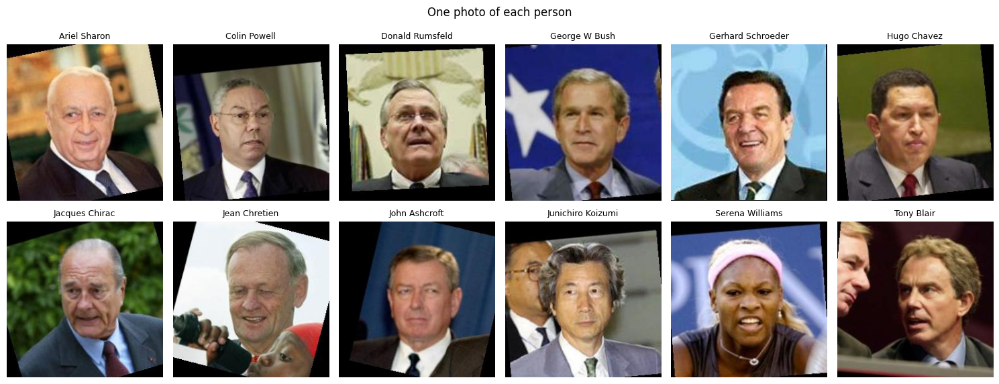

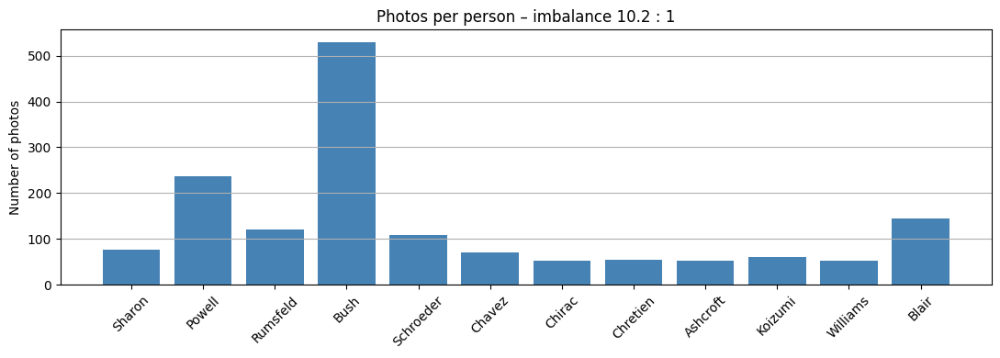

In [ ]:
# ============================================================
# 3. SAMPLE IMAGES AND CLASS DISTRIBUTION
# ============================================================

plt.figure(figsize=(15, 6))
for i in range(NUM_CLASSES):
    index = np.where(Y_all == i)[0][0]
    plt.subplot(2, 6, i + 1)
    plt.imshow(images[index])
    plt.title(class_names[i], fontsize=9)
    plt.axis("off")
plt.suptitle("One photo of each person")
plt.tight_layout()
save_show("01_sample_images")

counts = np.bincount(Y_all)
plt.figure(figsize=(11, 4))
plt.bar(short_names, counts, color="steelblue")
plt.xticks(rotation=45)
plt.ylabel("Number of photos")
plt.title(f"Photos per person – imbalance {counts.max() / counts.min():.1f} : 1")
plt.grid(axis="y")
plt.tight_layout()
save_show("02_class_distribution")

## 3. Face Detection

### 3.1 Haar Cascade (Viola–Jones)
1. **Haar features** – black/white rectangles that measure brightness differences (eyes darker than cheeks).
2. **Integral image** – any rectangle sum in constant time.
3. **AdaBoost** – selects the most useful features.
4. **Cascade** – a sliding window passes through stages; non-faces are rejected early → real time on a CPU.

`scaleFactor=1.1` (search many sizes), `minNeighbors=5` (fewer false detections), `minSize=(40,40)`. Histogram equalisation reduces lighting effects.
After detection we **crop with a 20% margin** (keeps chin and forehead) and resize to **160 × 160**.

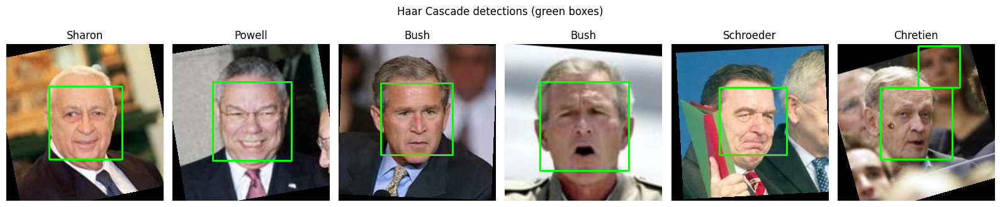

In [ ]:
# ============================================================
# 4. FACE DETECTION FUNCTIONS (HAAR CASCADE)
# ============================================================

face_cascade = cv2.CascadeClassifier(cv2.data.haarcascades + "haarcascade_frontalface_default.xml")
FALLBACK_BOX = (75, 75, 100, 100)          # approximate face position in a 250x250 LFW photo


def detect_faces(image):
    """Haar cascade -> list of face boxes (x, y, w, h).
    Big photos are searched on a 640 px copy (much faster); LFW photos (250 px) are unchanged."""
    k = max(image.shape[:2]) / 640
    if k > 1:
        small = cv2.resize(image, (int(image.shape[1] / k), int(image.shape[0] / k)), interpolation=cv2.INTER_AREA)
        gray = cv2.equalizeHist(cv2.cvtColor(small, cv2.COLOR_RGB2GRAY))
        faces = face_cascade.detectMultiScale(gray, scaleFactor=1.1, minNeighbors=5, minSize=(24, 24))
        return [tuple(int(round(v * k)) for v in face) for face in faces]
    gray = cv2.equalizeHist(cv2.cvtColor(image, cv2.COLOR_RGB2GRAY))
    faces = face_cascade.detectMultiScale(gray, scaleFactor=1.1, minNeighbors=5, minSize=(40, 40))
    return [tuple(int(v) for v in face) for face in faces]


def crop_face(image, box, margin=0.2):
    """Crop the face with a 20% margin and resize to IMG_SIZE x IMG_SIZE."""
    x, y, w, h = box
    H, W = image.shape[:2]
    mx, my = int(w * margin), int(h * margin)
    x1, y1 = max(0, x - mx), max(0, y - my)
    x2, y2 = min(W, x + w + mx), min(H, y + h + my)
    if x2 - x1 < 2 or y2 - y1 < 2:               # bad box -> whole image
        x1, y1, x2, y2 = 0, 0, W, H
    return cv2.resize(image[y1:y2, x1:x2], (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)


def central_box(boxes, shape):
    """LFW photos are centred on the labelled person -> choose the box nearest the centre."""
    cy, cx = shape[0] / 2, shape[1] / 2
    return min(boxes, key=lambda b: (b[0] + b[2] / 2 - cx) ** 2 + (b[1] + b[3] / 2 - cy) ** 2)


def get_face(image):
    """Detect -> choose the central face -> crop. Uses a centre crop if no face is found."""
    boxes = detect_faces(image)
    if len(boxes) == 0:
        return crop_face(image, FALLBACK_BOX), False
    return crop_face(image, central_box(boxes, image.shape)), True


plt.figure(figsize=(16, 3.5))
for i in range(6):
    index = i * 250
    image = images[index].copy()
    for (x, y, w, h) in detect_faces(image):
        cv2.rectangle(image, (x, y), (x + w, y + h), (0, 255, 0), 2)
    plt.subplot(1, 6, i + 1)
    plt.imshow(image)
    plt.title(short_names[Y_all[index]])
    plt.axis("off")
plt.suptitle("Haar Cascade detections (green boxes)")
plt.tight_layout()
save_show("03_haar_detections")

Face crops shape : (1560, 160, 160, 3)
Detection rate   : 99.2%  (12 photos used the centre crop)
Detection time   : 29.7 ms per photo (CPU)


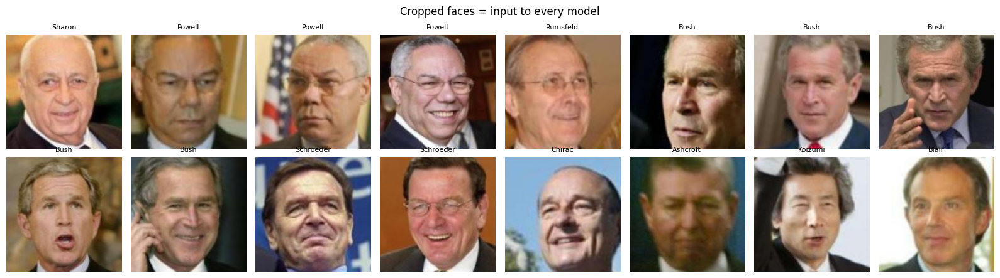

In [ ]:
# ============================================================
# 5. CROP THE FACE FROM EVERY PHOTO
# ============================================================

X_faces, detected = [], []
start = time.time()
for image in images:
    face, found = get_face(image)
    X_faces.append(face)
    detected.append(found)
haar_ms = (time.time() - start) * 1000 / len(images)

X_faces = np.array(X_faces, dtype="uint8")
detected = np.array(detected)
detection_rate = detected.mean() * 100

print("Face crops shape :", X_faces.shape)
print(f"Detection rate   : {detection_rate:.1f}%  ({np.sum(~detected)} photos used the centre crop)")
print(f"Detection time   : {haar_ms:.1f} ms per photo (CPU)")

plt.figure(figsize=(16, 4.5))
for i in range(16):
    index = i * 97
    plt.subplot(2, 8, i + 1)
    plt.imshow(X_faces[index])
    plt.title(short_names[Y_all[index]], fontsize=8)
    plt.axis("off")
plt.suptitle("Cropped faces = input to every model")
plt.tight_layout()
save_show("04_cropped_faces")

### 3.2 YuNet – a modern CNN face detector, and crop calibration
**YuNet** is a tiny (~75k parameter) CNN detector built into OpenCV. It was *trained* on thousands of faces, so it copes better with turned heads and bad lighting.

LFW has no box labels, but every photo is centred on the labelled person, so we count a **hit** when the detected box is within 30 px of the centre.

**Crop calibration:** all models are trained on Haar-framed crops. YuNet draws tighter boxes, so its crops look different, which is a train/test mismatch. From photos where both detectors agree, we learn a small correction (scale and shift) that makes YuNet crops look like Haar crops. Section 9.6 measures the effect on recognition accuracy.

              Face found (%)  Centre hit (%)  Photos with >1 face (%)  \
Haar Cascade            99.2            99.0                      9.9   
YuNet (CNN)            100.0            99.6                     16.0   

              ms / photo  
Haar Cascade        26.5  
YuNet (CNN)          5.5  

Calibration learnt from 1544 photos: {'sw': 1.237, 'sh': 0.918, 'dx': 0.006, 'dy': -0.032}
Haar missed the labelled face in 15 photos; YuNet found 14 of them.


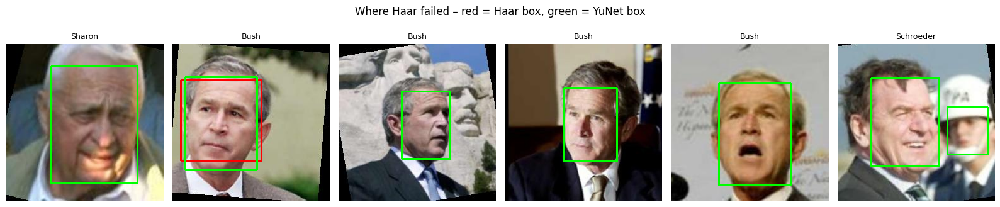

In [ ]:
# ============================================================
# 6. YUNET DETECTOR, COMPARISON AND CALIBRATION
# ============================================================

YUNET_URL = ("https://github.com/opencv/opencv_zoo/raw/main/models/"
             "face_detection_yunet/face_detection_yunet_2023mar.onnx")
yunet = None
try:
    if not os.path.exists("yunet.onnx"):
        urllib.request.urlretrieve(YUNET_URL, "yunet.onnx")
    yunet = cv2.FaceDetectorYN.create("yunet.onnx", "", (250, 250), 0.7, 0.3, 5000)
except Exception as e:
    print("YuNet not available (needs internet and OpenCV >= 4.8) -> Haar only:", e)


def detect_faces_yunet(image):
    h, w = image.shape[:2]
    yunet.setInputSize((w, h))
    _, detections = yunet.detect(cv2.cvtColor(image, cv2.COLOR_RGB2BGR))
    return [] if detections is None else [tuple(int(v) for v in d[:4]) for d in detections]


YUNET_CAL = {"sw": 1.0, "sh": 1.0, "dx": 0.0, "dy": 0.0}

def calibrate_box(box):
    """Re-frame a YuNet box so that the crop looks like a Haar crop."""
    x, y, w, h = box
    cx = x + w / 2 + YUNET_CAL["dx"] * w
    cy = y + h / 2 + YUNET_CAL["dy"] * h
    w2, h2 = w * YUNET_CAL["sw"], h * YUNET_CAL["sh"]
    return (int(round(cx - w2 / 2)), int(round(cy - h2 / 2)), int(round(w2)), int(round(h2)))


def pipeline_boxes(image, detector="haar"):
    """Face boxes used by the final system ('yunet' boxes are calibrated)."""
    if detector == "yunet" and yunet is not None:
        return [calibrate_box(b) for b in detect_faces_yunet(image)]
    return detect_faces(image)


def iou(a, b):
    ix = max(0, min(a[0] + a[2], b[0] + b[2]) - max(a[0], b[0]))
    iy = max(0, min(a[1] + a[3], b[1] + b[3]) - max(a[1], b[1]))
    inter = ix * iy
    return inter / (a[2] * a[3] + b[2] * b[3] - inter + 1e-9)


def centre_hit(box, tolerance=30):
    return box is not None and np.hypot(box[0] + box[2] / 2 - 125, box[1] + box[3] / 2 - 125) <= tolerance


DETECTOR_TABLE = None
if yunet is not None:
    detector_results = {}
    for name, detector in [("Haar Cascade", detect_faces), ("YuNet (CNN)", detect_faces_yunet)]:
        start = time.time()
        boxes_list = [detector(image) for image in images]
        ms = (time.time() - start) * 1000 / len(images)
        central = [central_box(b, (250, 250)) if b else None for b in boxes_list]
        detector_results[name] = {"central": central,
                                  "Face found (%)": np.mean([c is not None for c in central]) * 100,
                                  "Centre hit (%)": np.mean([centre_hit(c) for c in central]) * 100,
                                  "Photos with >1 face (%)": np.mean([len(b) > 1 for b in boxes_list]) * 100,
                                  "ms / photo": ms}
    DETECTOR_TABLE = pd.DataFrame({name: {k: round(v, 1) for k, v in r.items() if k != "central"}
                                   for name, r in detector_results.items()}).T
    print(DETECTOR_TABLE)

    # Learn the calibration from photos where both detectors agree
    agree = [(a, b) for a, b in zip(detector_results["Haar Cascade"]["central"], detector_results["YuNet (CNN)"]["central"])
             if a and b and iou(a, b) > 0.3]
    YUNET_CAL = {"sw": float(np.median([a[2] / b[2] for a, b in agree])),
                 "sh": float(np.median([a[3] / b[3] for a, b in agree])),
                 "dx": float(np.median([((a[0] + a[2] / 2) - (b[0] + b[2] / 2)) / b[2] for a, b in agree])),
                 "dy": float(np.median([((a[1] + a[3] / 2) - (b[1] + b[3] / 2)) / b[3] for a, b in agree]))}
    print(f"\nCalibration learnt from {len(agree)} photos:", {k: round(v, 3) for k, v in YUNET_CAL.items()})

    haar_missed = [i for i, c in enumerate(detector_results["Haar Cascade"]["central"]) if not centre_hit(c)]
    print(f"Haar missed the labelled face in {len(haar_missed)} photos; YuNet found "
          f"{sum(centre_hit(detector_results['YuNet (CNN)']['central'][i]) for i in haar_missed)} of them.")
    if haar_missed:
        plt.figure(figsize=(16, 3.5))
        for k, i in enumerate(haar_missed[:6]):
            image = images[i].copy()
            for (x, y, w, h) in detect_faces(image):
                cv2.rectangle(image, (x, y), (x + w, y + h), (255, 0, 0), 2)
            for (x, y, w, h) in detect_faces_yunet(image):
                cv2.rectangle(image, (x, y), (x + w, y + h), (0, 255, 0), 2)
            plt.subplot(1, 6, k + 1)
            plt.imshow(image)
            plt.title(short_names[Y_all[i]], fontsize=9)
            plt.axis("off")
        plt.suptitle("Where Haar failed – red = Haar box, green = YuNet box")
        plt.tight_layout()
        save_show("05_detector_failures")

## 4. Data Splits, Class Weights and Normalisation

| Split | Size | Used for |
|---|---|---|
| Train | 70% | learning the weights |
| Validation | 7.5% | EarlyStopping and choosing the best seed |
| **Calibration** | 7.5% | choosing the "Unknown" threshold only |
| Test | 15% | **final results only** |

Every decision is made on its own data, so the test results are never optimistic. `stratify` keeps every person's proportion the same in all splits.
**Class weights:** Bush has ~530 photos, others 50–70. Balanced weights make mistakes on rare people cost more.

In [ ]:
# ============================================================
# 7. TRAIN / VALIDATION / CALIBRATION / TEST SPLIT
# ============================================================

indices = np.arange(len(X_faces))
train_idx, temp_idx = train_test_split(indices, test_size=0.30, stratify=Y_all, random_state=SEED)
val_idx, test_idx   = train_test_split(temp_idx, test_size=0.50, stratify=Y_all[temp_idx], random_state=SEED)
val_idx, cal_idx    = train_test_split(val_idx, test_size=0.50, stratify=Y_all[val_idx], random_state=SEED)

X_train, Y_train = X_faces[train_idx], Y_all[train_idx]
X_val,   Y_val   = X_faces[val_idx],   Y_all[val_idx]
X_cal,   Y_cal   = X_faces[cal_idx],   Y_all[cal_idx]
X_test,  Y_test  = X_faces[test_idx],  Y_all[test_idx]

print("X_train:", X_train.shape, " X_val:", X_val.shape, " X_cal:", X_cal.shape, " X_test:", X_test.shape)


# ============================================================
# 8. CLASS WEIGHTS
# ============================================================

weights = compute_class_weight("balanced", classes=np.arange(NUM_CLASSES), y=Y_train)
class_weights = dict(enumerate(weights))
for i in range(NUM_CLASSES):
    print(f"{class_names[i]:28s} weight = {weights[i]:.2f}")


# ============================================================
# 9. INPUT ARRAYS
# ============================================================

# CNNs from scratch: pixels 0-255 -> 0-1
x_train, x_val, x_test = [(X / 255.0).astype("float32") for X in (X_train, X_val, X_test)]   # float32 saves RAM

# MobileNetV2: raw 0-255 float pixels (scaling to [-1, 1] happens INSIDE the model,
# so the saved model can be given a normal photo directly)
X_train_f, X_val_f, X_cal_f, X_test_f = [X.astype("float32") for X in (X_train, X_val, X_cal, X_test)]


def early_stop(patience=8):
    """Stop when validation accuracy stops improving and restore the best weights."""
    return keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=patience, restore_best_weights=True)

X_train: (1092, 160, 160, 3)  X_val: (117, 160, 160, 3)  X_cal: (117, 160, 160, 3)  X_test: (234, 160, 160, 3)
Ariel Sharon                 weight = 1.69
Colin Powell                 weight = 0.55
Donald Rumsfeld              weight = 1.07
George W Bush                weight = 0.25
Gerhard Schroeder            weight = 1.20
Hugo Chavez                  weight = 1.82
Jacques Chirac               weight = 2.53
Jean Chretien                weight = 2.33
John Ashcroft                weight = 2.46
Junichiro Koizumi            weight = 2.17
Serena Williams              weight = 2.53
Tony Blair                   weight = 0.90


## 5. Model 1 – Basic CNN (from scratch)
**Conv → Pool → Conv → Pool → Flatten → Dense → Softmax**
* **Conv2D** learns local patterns (edges → eyes, nose → face parts). **MaxPooling** halves the size and keeps strong features.
* **Flatten** turns feature maps into a vector. **Softmax** gives one probability per person.
* Loss: **sparse categorical cross-entropy** (integer labels). Optimizer: **Adam**.

In [ ]:
# ============================================================
# 10. BASIC CNN
# ============================================================

basic_cnn = keras.Sequential([
    layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
    layers.Conv2D(16, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dense(NUM_CLASSES, activation="softmax")
], name="basic_cnn")
basic_cnn.summary()

basic_cnn.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])

start = time.time()
basic_history = basic_cnn.fit(
    x_train, Y_train,
    validation_data=(x_val, Y_val),
    epochs=25, batch_size=32,
    class_weight=class_weights,
    callbacks=[early_stop()]
)
basic_time = time.time() - start

basic_loss, basic_accuracy = basic_cnn.evaluate(x_test, Y_test)
print("\nBasic CNN test accuracy:", basic_accuracy)

Model: "basic_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 158, 158, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 79, 79, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 77, 77, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 38, 38, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 46208)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 64)             │     2,957,376 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 12)             │           780 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,963,244 (11.30 MB)

 Trainable params: 2,963,244 (11.30 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/25
35/35 ━━━━━━━━━━━━━━━━━━━━ 5s 85ms/step - accuracy: 0.0943 - loss: 2.5219 - val_accuracy: 0.0342 - val_loss: 2.4615
Epoch 2/25
35/35 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.2738 - loss: 2.0526 - val_accuracy: 0.2991 - val_loss: 1.9316
Epoch 3/25
35/35 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - accuracy: 0.5696 - loss: 1.1824 - val_accuracy: 0.5385 - val_loss: 1.2632
Epoch 4/25
35/35 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.7738 - loss: 0.5679 - val_accuracy: 0.7692 - val_loss: 0.7042
Epoch 5/25
35/35 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.8727 - loss: 0.2994 - val_accuracy: 0.7863 - val_loss: 0.5952
Epoch 6/25
35/35 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - accuracy: 0.9377 - loss: 0.1500 - val_accuracy: 0.8291 - val_loss: 0.5585
Epoch 7/25
35/35 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.9734 - loss: 0.0836 - val_accuracy: 0.8034 - val_loss: 0.4712
Epoch 8/25
35/35 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.9771 - loss: 0.0574 - val_accuracy: 0.8632 - v

## 6. Model 2 – Improved CNN (BatchNorm + Dropout + Data Augmentation)
* **Data augmentation** – random flip, rotation, zoom and shift create new versions of each training face (training only) → less overfitting.
* **BatchNormalization** – normalises each layer's output → faster, more stable training.
* **Dropout(0.5)** – randomly switches off neurons during training → less overfitting.
* **GlobalAveragePooling** – one number per feature map → far fewer parameters than Flatten.

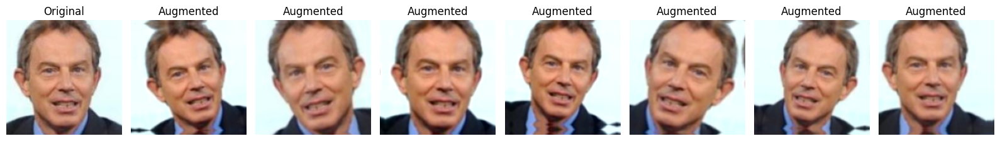

Model: "improved_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 160, 160, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 160, 160, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu1 (Activation)              │ (None, 160, 160, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 80, 80, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 80, 80, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 80, 80, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu2 (Activation)              │ (None, 80, 80, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 40, 40, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3 (Conv2D)                  │ (None, 40, 40, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 40, 40, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu3 (Activation)              │ (None, 40, 40, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_25 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 12)             │         1,548 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 112,716 (440.30 KB)

 Trainable params: 112,012 (437.55 KB)

 Non-trainable params: 704 (2.75 KB)

Epoch 1/40
35/35 ━━━━━━━━━━━━━━━━━━━━ 6s 83ms/step - accuracy: 0.1007 - loss: 2.8235 - val_accuracy: 0.0598 - val_loss: 2.4961
Epoch 2/40
35/35 ━━━━━━━━━━━━━━━━━━━━ 3s 72ms/step - accuracy: 0.1447 - loss: 2.5441 - val_accuracy: 0.1709 - val_loss: 2.4180
Epoch 3/40
35/35 ━━━━━━━━━━━━━━━━━━━━ 5s 73ms/step - accuracy: 0.1383 - loss: 2.4358 - val_accuracy: 0.3162 - val_loss: 2.3220
Epoch 4/40
35/35 ━━━━━━━━━━━━━━━━━━━━ 3s 72ms/step - accuracy: 0.1777 - loss: 2.3359 - val_accuracy: 0.1538 - val_loss: 2.3385
Epoch 5/40
35/35 ━━━━━━━━━━━━━━━━━━━━ 3s 72ms/step - accuracy: 0.2161 - loss: 2.1254 - val_accuracy: 0.1453 - val_loss: 2.4048
Epoch 6/40
35/35 ━━━━━━━━━━━━━━━━━━━━ 5s 75ms/step - accuracy: 0.2060 - loss: 2.1606 - val_accuracy: 0.1538 - val_loss: 2.3941
Epoch 7/40
35/35 ━━━━━━━━━━━━━━━━━━━━ 3s 73ms/step - accuracy: 0.2152 - loss: 2.0826 - val_accuracy: 0.1538 - val_loss: 2.6773
Epoch 8/40
35/35 ━━━━━━━━━━━━━━━━━━━━ 3s 73ms/step - accuracy: 0.2326 - loss: 1.9848 - val_accuracy: 0.1624 - v

In [ ]:
# ============================================================
# 11. DATA AUGMENTATION
# ============================================================

def make_augmentation():
    return keras.Sequential([
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.05),            # +/- 18 degrees
        layers.RandomZoom(0.1),
        layers.RandomTranslation(0.05, 0.05),
        layers.RandomContrast(0.2)
    ], name="data_augmentation")

augment = make_augmentation()
plt.figure(figsize=(16, 2.5))
plt.subplot(1, 8, 1)
plt.imshow(X_train[0])
plt.title("Original")
plt.axis("off")
for i in range(7):
    augmented = np.array(augment(X_train_f[0:1], training=True)[0])
    plt.subplot(1, 8, i + 2)
    plt.imshow(np.clip(augmented, 0, 255).astype("uint8"))
    plt.title("Augmented")
    plt.axis("off")
plt.tight_layout()
save_show("06_augmentation")


# ============================================================
# 12. IMPROVED CNN
# ============================================================

improved_cnn = keras.Sequential([
    layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
    make_augmentation(),

    layers.Conv2D(32, 3, padding="same", name="conv1"),
    layers.BatchNormalization(),
    layers.Activation("relu", name="relu1"),
    layers.MaxPooling2D(2),

    layers.Conv2D(64, 3, padding="same", name="conv2"),
    layers.BatchNormalization(),
    layers.Activation("relu", name="relu2"),
    layers.MaxPooling2D(2),

    layers.Conv2D(128, 3, padding="same", name="conv3"),
    layers.BatchNormalization(),
    layers.Activation("relu", name="relu3"),
    layers.MaxPooling2D(2),

    layers.GlobalAveragePooling2D(),
    layers.Dense(128),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.Dropout(0.5),
    layers.Dense(NUM_CLASSES, activation="softmax")
], name="improved_cnn")
improved_cnn.summary()

improved_cnn.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])

start = time.time()
improved_history = improved_cnn.fit(
    x_train, Y_train,
    validation_data=(x_val, Y_val),
    epochs=40, batch_size=32,
    class_weight=class_weights,
    callbacks=[early_stop(10)]
)
improved_time = time.time() - start

improved_loss, improved_accuracy = improved_cnn.evaluate(x_test, Y_test)
print("\nImproved CNN test accuracy:", improved_accuracy)

Selected layer    : relu1
Feature map shape : (1, 160, 160, 32)


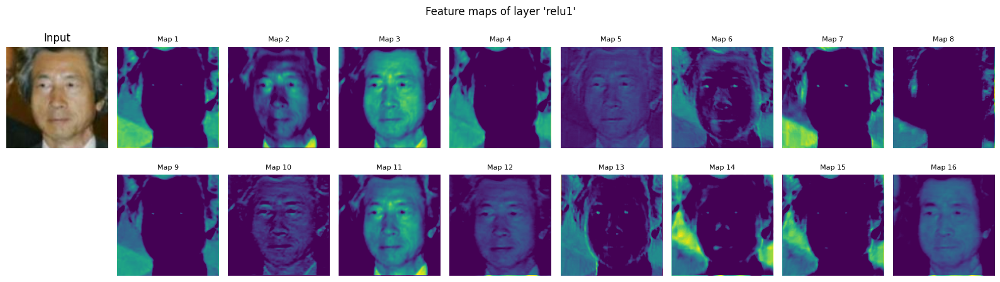

In [ ]:
# ============================================================
# 13. FEATURE MAPS – what the convolution filters see
# ============================================================

layer_name = "relu1"            # change to relu2 / relu3 to look deeper
image_index = 0
max_feature_maps = 16

selected_layer = improved_cnn.get_layer(layer_name)
layer_index = improved_cnn.layers.index(selected_layer)
feature_extractor = keras.Sequential(improved_cnn.layers[:layer_index + 1])
feature_maps = feature_extractor.predict(x_test[image_index:image_index + 1], verbose=0)

print("Selected layer    :", layer_name)
print("Feature map shape :", feature_maps.shape)

number_to_display = min(feature_maps.shape[-1], max_feature_maps)
plt.figure(figsize=(16, 4.8))
plt.subplot(2, 9, 1)
plt.imshow(X_test[image_index])
plt.title("Input")
plt.axis("off")
for i in range(number_to_display):
    plt.subplot(2, 9, i + 2 + (i >= 8))
    plt.imshow(feature_maps[0, :, :, i], cmap="viridis")
    plt.title("Map " + str(i + 1), fontsize=8)
    plt.axis("off")
plt.suptitle(f"Feature maps of layer '{layer_name}'")
plt.tight_layout()
save_show("07_feature_maps")

## 7. Model 3 – MobileNetV2 Transfer Learning (MAIN MODEL)

**Why MobileNetV2?**
* Pre-trained on **ImageNet** (1.4 million images), so it already knows edges, textures and shapes. Our ~1,100 training faces are far too few to learn these from scratch.
* **Lightweight** (2.3 M parameters vs 14.7 M for VGG16) → fast enough for a phone, Raspberry Pi or attendance camera.

**MobileNetV2 building block – inverted residual with linear bottleneck:**
`1×1 conv (expand ×6) → 3×3 depthwise conv → 1×1 conv (project, no ReLU) → + skip connection`
* **Depthwise separable convolution** = one 3×3 filter per channel + a 1×1 conv to mix channels → ~8–9× fewer calculations than a normal convolution.

**Our model:**
```
Input 160×160×3 → Augmentation → Rescaling to [-1, 1] → MobileNetV2 (ImageNet) → 5×5×1280
→ GlobalAveragePooling → Dropout 0.3 → Dense 256 ("embedding") → Dropout 0.4 → Dense 12 (softmax)
```
**Two-stage training** (same method as the VGG16 notebook in class):
1. **Feature extraction** – base frozen, train only the new layers (Adam, lr = 1e-3).
2. **Fine-tuning** – unfreeze the **last 40 layers**, train with **lr = 1e-5**. BatchNorm layers stay frozen so their statistics stay stable.

### 7.1 Model 5 – MobileNetV2 + ArcFace
Softmax only learns to *separate the 12 training people*. **ArcFace** (used in modern face-recognition systems) adds an **angular margin m** to the correct person during training:

$$L = -\log \frac{e^{s\cos(\theta_y + m)}}{e^{s\cos(\theta_y + m)} + \sum_{j\neq y} e^{s\cos\theta_j}}, \quad s = 30,\ m = 0.3$$

The face must be closer (in angle) to its own person than to anyone else **by at least m**. This makes tight, well-separated clusters, which helps with strangers and new people (tested in Sections 13–15).

### 7.2 Ablation study
To **prove** which parts help, MobileNetV2 is trained 4 ways, each with every seed in `SEEDS`: full model · no augmentation · no class weights · ArcFace. "Frozen only" results are recorded at the end of stage 1.

In [ ]:
# ============================================================
# 14. MOBILENETV2 BUILDING FUNCTIONS
# ============================================================

FINE_TUNE_LAYERS = 40
ARC_S, ARC_M = 30.0, 0.30
COS_M, SIN_M = float(np.cos(ARC_M)), float(np.sin(ARC_M))
ARC_TH, ARC_MM = float(np.cos(np.pi - ARC_M)), float(np.sin(np.pi - ARC_M) * ARC_M)


class CosineLayer(layers.Layer):
    """ArcFace head: cosine between the normalised embedding and each normalised person-centre W."""
    def __init__(self, num_classes, **kwargs):
        super().__init__(**kwargs)
        self.num_classes = num_classes

    def build(self, input_shape):
        self.W = self.add_weight(name="W", shape=(int(input_shape[-1]), self.num_classes),
                                 initializer="glorot_uniform", trainable=True)

    def call(self, x):
        return tf.matmul(tf.math.l2_normalize(x, axis=1), tf.math.l2_normalize(self.W, axis=0))


def arcface_loss(y_true, cos):
    """Adds the angular margin m to the correct person, then normal cross-entropy."""
    y = tf.cast(tf.reshape(y_true, [-1]), tf.int32)
    cos = tf.clip_by_value(tf.cast(cos, tf.float32), -1.0 + 1e-7, 1.0 - 1e-7)
    sin = tf.sqrt(1.0 - cos * cos)
    cos_margin = cos * COS_M - sin * SIN_M                         # cos(theta + m)
    cos_margin = tf.where(cos > ARC_TH, cos_margin, cos - ARC_MM)
    onehot = tf.one_hot(y, NUM_CLASSES)
    logits = ARC_S * (onehot * cos_margin + (1.0 - onehot) * cos)
    return tf.nn.sparse_softmax_cross_entropy_with_logits(labels=y, logits=logits)


def build_mobilenet(augment=True, head="softmax"):
    base = keras.applications.MobileNetV2(input_shape=(IMG_SIZE, IMG_SIZE, 3), include_top=False, weights="imagenet")
    base.trainable = False

    model_layers = [layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))]
    if augment:
        model_layers.append(make_augmentation())
    model_layers += [layers.Rescaling(1.0 / 127.5, offset=-1, name="rescale"),     # MobileNetV2 expects [-1, 1]
                     base,
                     layers.GlobalAveragePooling2D(name="gap"),
                     layers.Dropout(0.3)]
    if head == "softmax":
        model_layers += [layers.Dense(256, activation="relu", name="embedding"),
                         layers.Dropout(0.4),
                         layers.Dense(NUM_CLASSES, activation="softmax", name="classifier")]
    else:
        model_layers += [layers.Dense(256, name="embedding_dense"),
                         layers.BatchNormalization(name="embedding"),
                         CosineLayer(NUM_CLASSES, name="classifier")]
    return keras.Sequential(model_layers, name=f"mobilenetv2_{head}"), base


def predict_probs(model, X, head="softmax"):
    output = model.predict(X, batch_size=64, verbose=0)
    if head == "arcface":                                           # cosines -> probabilities
        output = tf.nn.softmax(ARC_S * output).numpy()
    return output


def train_mobilenet(seed, augment=True, use_class_weights=True, head="softmax"):
    keras.utils.set_random_seed(seed)
    model, base = build_mobilenet(augment, head)
    loss = arcface_loss if head == "arcface" else "sparse_categorical_crossentropy"
    cw = class_weights if use_class_weights else None
    start = time.time()

    # Stage 1: feature extraction (base frozen)
    model.compile(optimizer=keras.optimizers.Adam(1e-3), loss=loss,
                  metrics=[keras.metrics.SparseCategoricalAccuracy(name="accuracy")])
    h1 = model.fit(X_train_f, Y_train, validation_data=(X_val_f, Y_val), epochs=15, batch_size=32,
                   class_weight=cw, callbacks=[early_stop(6)], verbose=0)
    frozen_test_probs = predict_probs(model, X_test_f, head)

    # Stage 2: fine-tuning (last 40 layers, BatchNorm stays frozen)
    base.trainable = True
    for layer in base.layers[:-FINE_TUNE_LAYERS]:
        layer.trainable = False
    for layer in base.layers:
        if isinstance(layer, layers.BatchNormalization):
            layer.trainable = False
    model.compile(optimizer=keras.optimizers.Adam(1e-5), loss=loss,
                  metrics=[keras.metrics.SparseCategoricalAccuracy(name="accuracy")])
    h2 = model.fit(X_train_f, Y_train, validation_data=(X_val_f, Y_val), epochs=20, batch_size=32,
                   class_weight=cw, callbacks=[early_stop(8)], verbose=0)

    val_probs = predict_probs(model, X_val_f, head)
    return {"model": model, "base": base, "head": head, "seed": seed,
            "history1": h1.history, "history2": h2.history,
            "epochs": len(h1.history["loss"]) + len(h2.history["loss"]),
            "time": time.time() - start,
            "val_accuracy": accuracy_score(Y_val, val_probs.argmax(1)),
            "test_probs": predict_probs(model, X_test_f, head),
            "frozen_test_probs": frozen_test_probs}


demo_model, demo_base = build_mobilenet()
demo_model.summary()
print("Layers in the MobileNetV2 base:", len(demo_base.layers))
del demo_model, demo_base
gc.collect()

Model: "mobilenetv2_softmax"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescale (Rescaling)             │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_26 (Dropout)            │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding (Dense)               │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_27 (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classifier (Dense)              │ (None, 12)             │         3,084 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,589,004 (9.88 MB)

 Trainable params: 331,020 (1.26 MB)

 Non-trainable params: 2,257,984 (8.61 MB)

Layers in the MobileNetV2 base: 154


260244

In [ ]:
# ============================================================
# 15. TRAIN MOBILENETV2 – ABLATION STUDY OVER SEEDS
# ============================================================

MNV2 = "MobileNetV2 (full)"
NO_AUG = "MobileNetV2 – no augmentation"
NO_CW = "MobileNetV2 – no class weights"
ARC = "MobileNetV2 + ArcFace"

EXPERIMENTS = {
    MNV2:   dict(augment=True,  use_class_weights=True,  head="softmax"),
    NO_AUG: dict(augment=False, use_class_weights=True,  head="softmax"),
    NO_CW:  dict(augment=True,  use_class_weights=False, head="softmax"),
    ARC:    dict(augment=True,  use_class_weights=True,  head="arcface"),
}

runs = {}
total_start = time.time()
for name, settings in EXPERIMENTS.items():
    runs[name] = []
    for seed in SEEDS:
        result = train_mobilenet(seed, **settings)
        test_pred = result["test_probs"].argmax(1)
        print(f"{name:32s} seed {seed:<5d} val acc {result['val_accuracy']:.3f}  "
              f"test acc {accuracy_score(Y_test, test_pred):.3f}  epochs {result['epochs']:2d}  {result['time'] / 60:.1f} min")
        runs[name].append(result)

    # keep only the run with the best VALIDATION accuracy (never choose using test data)
    best = int(np.argmax([r["val_accuracy"] for r in runs[name]]))
    for i, r in enumerate(runs[name]):
        if i != best:
            r["model"] = r["base"] = None
    gc.collect()

selected = {name: max(rs, key=lambda r: r["val_accuracy"]) for name, rs in runs.items()}
mnv2_model, mnv2_base = selected[MNV2]["model"], selected[MNV2]["base"]
arc_model = selected[ARC]["model"]
print(f"\nAll MobileNetV2 experiments: {(time.time() - total_start) / 60:.1f} min")
print("Selected seeds (best validation accuracy):", {k: v["seed"] for k, v in selected.items()})

MobileNetV2 (full)               seed 42    val acc 0.915  test acc 0.906  epochs 32  1.2 min
MobileNetV2 – no augmentation    seed 42    val acc 0.932  test acc 0.915  epochs 35  1.4 min
MobileNetV2 – no class weights   seed 42    val acc 0.940  test acc 0.910  epochs 35  1.4 min
MobileNetV2 + ArcFace            seed 42    val acc 0.949  test acc 0.889  epochs 32  1.3 min

All MobileNetV2 experiments: 5.6 min
Selected seeds (best validation accuracy): {'MobileNetV2 (full)': 42, 'MobileNetV2 – no augmentation': 42, 'MobileNetV2 – no class weights': 42, 'MobileNetV2 + ArcFace': 42}


## 8. Model 4 – VGG16 Transfer Learning (method from class)
Same steps as the Cats-vs-Dogs VGG16 notebook: `preprocess_input`, frozen base, then unfreeze the **last 4 layers** with **lr = 1e-5**. It is a strong comparison for MobileNetV2: is the 6× bigger model better?

In [ ]:
# ============================================================
# 16. VGG16
# ============================================================

def vgg_preprocess(faces):
    return keras.applications.vgg16.preprocess_input(np.asarray(faces).astype("float32"))

X_train_vgg, X_val_vgg, X_test_vgg = vgg_preprocess(X_train), vgg_preprocess(X_val), vgg_preprocess(X_test)

keras.utils.set_random_seed(SEED)
vgg_base = keras.applications.VGG16(weights="imagenet", include_top=False, input_shape=(IMG_SIZE, IMG_SIZE, 3))
vgg_base.trainable = False

vgg_model = keras.Sequential([
    layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
    make_augmentation(),
    vgg_base,
    layers.Flatten(),
    layers.Dense(256, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(NUM_CLASSES, activation="softmax")
], name="vgg16_face")
vgg_model.summary()

start = time.time()
vgg_model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
vgg_history = vgg_model.fit(X_train_vgg, Y_train, validation_data=(X_val_vgg, Y_val), epochs=15, batch_size=32,
                            class_weight=class_weights, callbacks=[early_stop(6)])
vgg_frozen_accuracy = vgg_model.evaluate(X_test_vgg, Y_test, verbose=0)[1]

vgg_base.trainable = True
for layer in vgg_base.layers[:-4]:
    layer.trainable = False
vgg_model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-5),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
vgg_finetune_history = vgg_model.fit(X_train_vgg, Y_train, validation_data=(X_val_vgg, Y_val), epochs=15,
                                     batch_size=32, class_weight=class_weights, callbacks=[early_stop(6)])
vgg_time = time.time() - start
vgg_accuracy = vgg_model.evaluate(X_test_vgg, Y_test, verbose=0)[1]

del X_train_vgg, X_val_vgg          # free RAM (only the test array is needed later)
gc.collect()

print(f"\nVGG16 frozen test accuracy    : {vgg_frozen_accuracy:.4f}")
print(f"VGG16 fine-tuned test accuracy: {vgg_accuracy:.4f}")

Model: "vgg16_face"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 5, 5, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 12800)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 256)            │     3,277,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_35 (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 12)             │         3,084 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 17,994,828 (68.64 MB)

 Trainable params: 3,280,140 (12.51 MB)

 Non-trainable params: 14,714,688 (56.13 MB)

Epoch 1/15
35/35 ━━━━━━━━━━━━━━━━━━━━ 6s 102ms/step - accuracy: 0.2070 - loss: 11.8149 - val_accuracy: 0.1368 - val_loss: 3.2964
Epoch 2/15
35/35 ━━━━━━━━━━━━━━━━━━━━ 3s 87ms/step - accuracy: 0.2079 - loss: 2.2470 - val_accuracy: 0.1624 - val_loss: 3.4574
Epoch 3/15
35/35 ━━━━━━━━━━━━━━━━━━━━ 3s 88ms/step - accuracy: 0.2793 - loss: 2.1085 - val_accuracy: 0.2137 - val_loss: 2.6208
Epoch 4/15
35/35 ━━━━━━━━━━━━━━━━━━━━ 3s 87ms/step - accuracy: 0.3745 - loss: 2.0044 - val_accuracy: 0.2051 - val_loss: 3.0021
Epoch 5/15
35/35 ━━━━━━━━━━━━━━━━━━━━ 3s 88ms/step - accuracy: 0.3993 - loss: 1.9455 - val_accuracy: 0.1966 - val_loss: 3.0271
Epoch 6/15
35/35 ━━━━━━━━━━━━━━━━━━━━ 3s 90ms/step - accuracy: 0.4295 - loss: 1.9019 - val_accuracy: 0.1368 - val_loss: 3.8616
Epoch 7/15
35/35 ━━━━━━━━━━━━━━━━━━━━ 3s 91ms/step - accuracy: 0.4386 - loss: 1.9243 - val_accuracy: 0.1880 - val_loss: 2.7316
Epoch 8/15
35/35 ━━━━━━━━━━━━━━━━━━━━ 3s 92ms/step - accuracy: 0.4505 - loss: 1.6858 - val_accuracy: 0.2308 -

## 9. Results

### 9.1 Training curves
Training and validation curves close together = good generalisation. Validation far below training = overfitting. The dashed line is where fine-tuning starts.

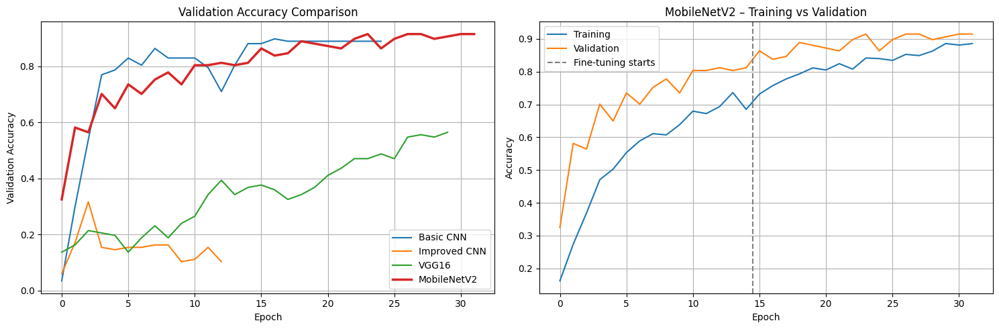

In [ ]:
# ============================================================
# 17. TRAINING CURVES
# ============================================================

mnv2_val = selected[MNV2]["history1"]["val_accuracy"] + selected[MNV2]["history2"]["val_accuracy"]
mnv2_train = selected[MNV2]["history1"]["accuracy"] + selected[MNV2]["history2"]["accuracy"]
vgg_val = vgg_history.history["val_accuracy"] + vgg_finetune_history.history["val_accuracy"]

plt.figure(figsize=(15, 5))
plt.subplot(1, 2, 1)
plt.plot(basic_history.history["val_accuracy"], label="Basic CNN")
plt.plot(improved_history.history["val_accuracy"], label="Improved CNN")
plt.plot(vgg_val, label="VGG16")
plt.plot(mnv2_val, label="MobileNetV2", linewidth=2.5)
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.title("Validation Accuracy Comparison")
plt.legend()
plt.grid()

plt.subplot(1, 2, 2)
plt.plot(mnv2_train, label="Training")
plt.plot(mnv2_val, label="Validation")
plt.axvline(len(selected[MNV2]["history1"]["accuracy"]) - 0.5, color="gray", linestyle="--", label="Fine-tuning starts")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("MobileNetV2 – Training vs Validation")
plt.legend()
plt.grid()
plt.tight_layout()
save_show("08_training_curves")

### 9.2 Model comparison and ablation study (test set)
* **Accuracy** is dominated by the biggest class (Bush). **Macro F1** treats all 12 people equally, so it is the fairer number.
* MobileNetV2 rows are **mean ± std over the seeds**. The Δ table compares runs **with the same seed** (fair pairs).

                         Model Test Accuracy (%) Macro F1 (×100) Parameters  Size (MB)  Runs
                     Basic CNN              89.3            85.4  2,963,244       11.9     1
                  Improved CNN              33.3             5.6    112,716        0.5     1
              VGG16 fine-tuned              49.1            38.4 17,994,828       72.0     1
     MobileNetV2 – frozen only              81.2            77.2  2,589,004       10.4     1
            MobileNetV2 (full)              90.6            87.6  2,589,004       10.4     1
 MobileNetV2 – no augmentation              91.5            89.6  2,589,004       10.4     1
MobileNetV2 – no class weights              91.0            86.5  2,589,004       10.4     1
         MobileNetV2 + ArcFace              88.9            86.2  2,590,016       10.4     1


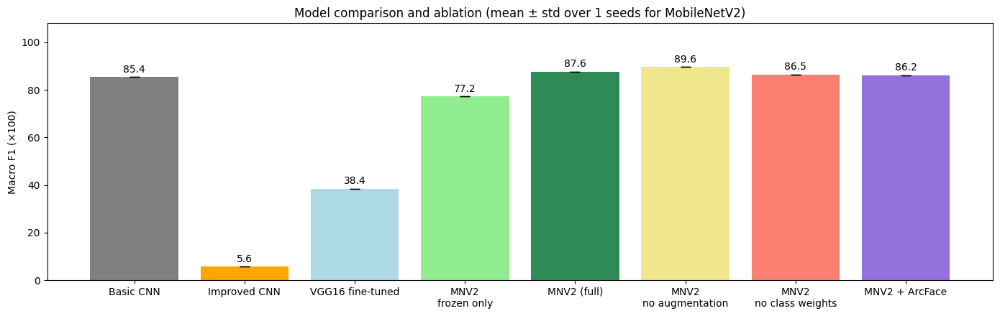

                 Component Macro-F1 change when included (points) Helped in
               Fine-tuning                            +10.4 ± 0.0 1/1 seeds
         Data augmentation                             -2.0 ± 0.0 0/1 seeds
             Class weights                             +1.1 ± 0.0 1/1 seeds
Softmax instead of ArcFace                             +1.4 ± 0.0 1/1 seeds


In [ ]:
# ============================================================
# 18. COMPARISON TABLE
# ============================================================

def scores(probs):
    predicted = probs.argmax(1)
    return accuracy_score(Y_test, predicted), f1_score(Y_test, predicted, average="macro")

def mean_std(values):
    return f"{np.mean(values) * 100:.1f} ± {np.std(values) * 100:.1f}" if len(values) > 1 else f"{values[0] * 100:.1f}"

comparison = {
    "Basic CNN":                 [scores(basic_cnn.predict(x_test, verbose=0))],
    "Improved CNN":              [scores(improved_cnn.predict(x_test, verbose=0))],
    "VGG16 fine-tuned":          [scores(vgg_model.predict(X_test_vgg, verbose=0))],
    "MobileNetV2 – frozen only": [scores(r["frozen_test_probs"]) for r in runs[MNV2]],
    MNV2:                        [scores(r["test_probs"]) for r in runs[MNV2]],
    NO_AUG:                      [scores(r["test_probs"]) for r in runs[NO_AUG]],
    NO_CW:                       [scores(r["test_probs"]) for r in runs[NO_CW]],
    ARC:                         [scores(r["test_probs"]) for r in runs[ARC]],
}
parameters = {"Basic CNN": basic_cnn.count_params(), "Improved CNN": improved_cnn.count_params(),
              "VGG16 fine-tuned": vgg_model.count_params()}
for name in [MNV2, NO_AUG, NO_CW, ARC, "MobileNetV2 – frozen only"]:
    parameters[name] = mnv2_model.count_params() if name != ARC else arc_model.count_params()

comparison_table = pd.DataFrame([{
    "Model": name,
    "Test Accuracy (%)": mean_std([a for a, f in values]),
    "Macro F1 (×100)": mean_std([f for a, f in values]),
    "Parameters": f"{parameters[name]:,}",
    "Size (MB)": round(parameters[name] * 4 / 1e6, 1),
    "Runs": len(values)} for name, values in comparison.items()])
print(comparison_table.to_string(index=False))
comparison_table.to_csv("comparison_table.csv", index=False)

plt.figure(figsize=(14, 4.5))
names = list(comparison)
means = [np.mean([f for a, f in comparison[n]]) * 100 for n in names]
stds = [np.std([f for a, f in comparison[n]]) * 100 for n in names]
colors = ["gray", "orange", "lightblue", "lightgreen", "seagreen", "khaki", "salmon", "mediumpurple"]
plt.bar([n.replace("MobileNetV2", "MNV2").replace(" – ", "\n") for n in names], means, yerr=stds, capsize=5, color=colors)
for i, v in enumerate(means):
    plt.text(i, v + 2, f"{v:.1f}", ha="center")
plt.ylim(0, 108)
plt.ylabel("Macro F1 (×100)")
plt.title(f"Model comparison and ablation (mean ± std over {len(SEEDS)} seeds for MobileNetV2)")
plt.tight_layout()
save_show("09_model_comparison")


# ============================================================
# 19. ABLATION – EFFECT OF EACH PART (paired by seed)
# ============================================================

full_f1 = np.array([f for a, f in comparison[MNV2]])
ablation_rows = []
for name, meaning in [("MobileNetV2 – frozen only", "Fine-tuning"), (NO_AUG, "Data augmentation"),
                      (NO_CW, "Class weights"), (ARC, "Softmax instead of ArcFace")]:
    delta = full_f1 - np.array([f for a, f in comparison[name]])
    ablation_rows.append({"Component": meaning,
                          "Macro-F1 change when included (points)": f"{delta.mean() * 100:+.1f} ± {delta.std() * 100:.1f}",
                          "Helped in": f"{int(np.sum(delta > 0))}/{len(delta)} seeds"})
ablation_table = pd.DataFrame(ablation_rows)
print(ablation_table.to_string(index=False))

### 9.3 Detailed evaluation of the selected MobileNetV2
* **95% confidence interval (bootstrap):** resample the test set 1,000 times. The range shows how much the score could change with a different test set of the same size.
* **McNemar test:** are two models *really* different on the same test faces? It counts faces where only one model is right. **p < 0.05 → significant.**

                   precision    recall  f1-score   support

     Ariel Sharon      0.688     1.000     0.815        11
     Colin Powell      0.972     1.000     0.986        35
  Donald Rumsfeld      1.000     0.889     0.941        18
    George W Bush      0.924     0.912     0.918        80
Gerhard Schroeder      0.875     0.824     0.848        17
      Hugo Chavez      0.900     0.818     0.857        11
   Jacques Chirac      1.000     0.625     0.769         8
    Jean Chretien      0.667     1.000     0.800         8
    John Ashcroft      0.833     0.625     0.714         8
Junichiro Koizumi      1.000     1.000     1.000         9
  Serena Williams      1.000     0.875     0.933         8
       Tony Blair      0.909     0.952     0.930        21

         accuracy                          0.906       234
        macro avg      0.897     0.877     0.876       234
     weighted avg      0.916     0.906     0.906       234



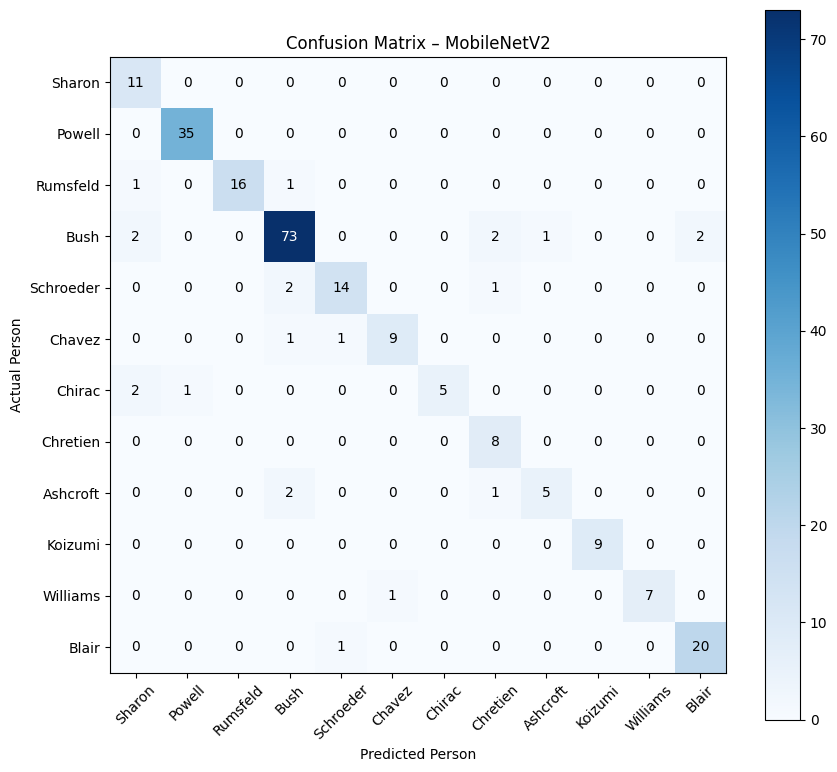

Test accuracy 90.60%   95% CI [86.8, 94.0]
Macro F1      0.876    95% CI [0.813, 0.927]
McNemar MobileNetV2 vs Basic CNN: only MNV2 right =  18, only Basic CNN right =  15, p = 0.728 -> not significant
McNemar MobileNetV2 vs VGG16    : only MNV2 right = 104, only VGG16 right =   7, p = 2.8e-23 -> SIGNIFICANT


In [ ]:
# ============================================================
# 20. CLASSIFICATION REPORT, CONFUSION MATRIX, STATISTICS
# ============================================================

test_probs = selected[MNV2]["test_probs"]
predicted_classes = test_probs.argmax(1)
print(classification_report(Y_test, predicted_classes, target_names=class_names, digits=3))

cm = confusion_matrix(Y_test, predicted_classes)
plt.figure(figsize=(9, 8))
plt.imshow(cm, cmap="Blues")
plt.colorbar()
plt.xlabel("Predicted Person")
plt.ylabel("Actual Person")
plt.title("Confusion Matrix – MobileNetV2")
plt.xticks(range(NUM_CLASSES), short_names, rotation=45)
plt.yticks(range(NUM_CLASSES), short_names)
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        plt.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.tight_layout()
save_show("10_confusion_matrix")

# ---- Bootstrap 95% confidence interval ----
rng_boot = np.random.RandomState(SEED)
boot_acc, boot_f1 = [], []
for _ in range(1000):
    sample = rng_boot.randint(0, len(Y_test), len(Y_test))
    boot_acc.append(accuracy_score(Y_test[sample], predicted_classes[sample]))
    boot_f1.append(f1_score(Y_test[sample], predicted_classes[sample], average="macro"))
acc_ci, f1_ci = np.percentile(boot_acc, [2.5, 97.5]), np.percentile(boot_f1, [2.5, 97.5])
mnv2_accuracy = accuracy_score(Y_test, predicted_classes)
print(f"Test accuracy {mnv2_accuracy * 100:.2f}%   95% CI [{acc_ci[0] * 100:.1f}, {acc_ci[1] * 100:.1f}]")
print(f"Macro F1      {f1_score(Y_test, predicted_classes, average='macro'):.3f}    95% CI [{f1_ci[0]:.3f}, {f1_ci[1]:.3f}]")

# ---- McNemar test ----
def mcnemar(pred_a, pred_b):
    only_a = int(np.sum((pred_a == Y_test) & (pred_b != Y_test)))
    only_b = int(np.sum((pred_a != Y_test) & (pred_b == Y_test)))
    p = 1.0 if only_a + only_b == 0 else stats.binomtest(min(only_a, only_b), only_a + only_b, 0.5).pvalue
    return only_a, only_b, p

mcnemar_results = {}
for other_name, other_pred in [("Basic CNN", basic_cnn.predict(x_test, verbose=0).argmax(1)),
                               ("VGG16", vgg_model.predict(X_test_vgg, verbose=0).argmax(1))]:
    a, b, p = mcnemar(predicted_classes, other_pred)
    mcnemar_results[other_name] = p
    print(f"McNemar MobileNetV2 vs {other_name:9s}: only MNV2 right = {a:3d}, only {other_name} right = {b:3d}, "
          f"p = {p:.3g} -> {'SIGNIFICANT' if p < 0.05 else 'not significant'}")

Correct predictions  : 212
Incorrect predictions: 22


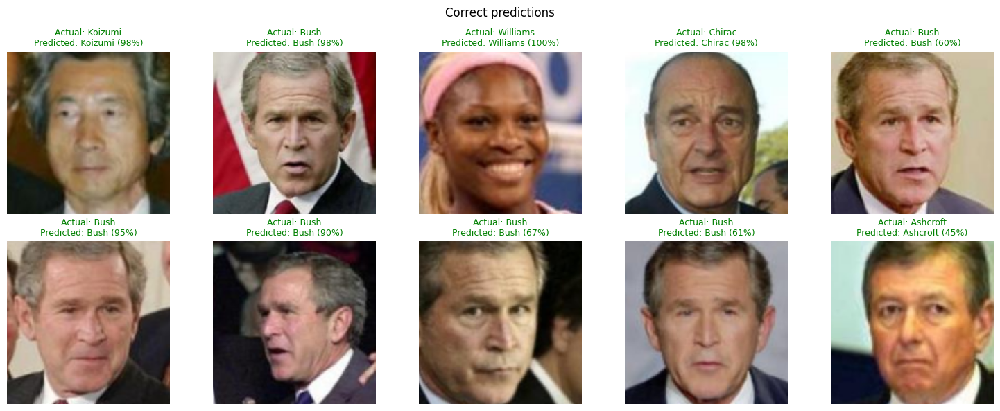

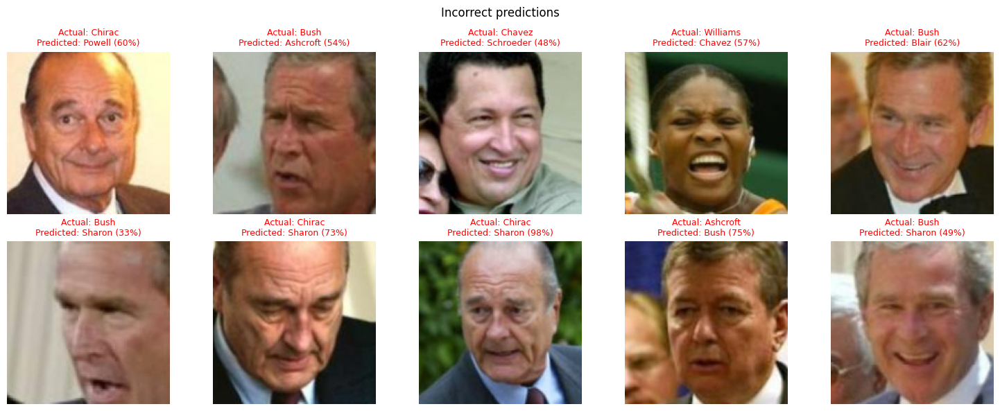


Most common mistakes:
  Gerhard Schroeder          -> predicted as George W Bush              2 times
  George W Bush              -> predicted as Tony Blair                 2 times
  George W Bush              -> predicted as Jean Chretien              2 times


In [ ]:
# ============================================================
# 21. CORRECT AND INCORRECT PREDICTIONS
# ============================================================

correct_indices = np.where(predicted_classes == Y_test)[0]
incorrect_indices = np.where(predicted_classes != Y_test)[0]
print("Correct predictions  :", len(correct_indices))
print("Incorrect predictions:", len(incorrect_indices))

for title, chosen, color, fname in [("Correct predictions", correct_indices, "green", "11_correct"),
                                    ("Incorrect predictions", incorrect_indices, "red", "12_incorrect")]:
    number_of_images = min(10, len(chosen))
    if number_of_images == 0:
        continue
    plt.figure(figsize=(15, 6))
    for i in range(number_of_images):
        index = chosen[i]
        plt.subplot(2, 5, i + 1)
        plt.imshow(X_test[index])
        plt.title(f"Actual: {short_names[Y_test[index]]}\nPredicted: {short_names[predicted_classes[index]]} "
                  f"({test_probs[index].max() * 100:.0f}%)", color=color, fontsize=9)
        plt.axis("off")
    plt.suptitle(title)
    plt.tight_layout()
    save_show(fname)

off_diagonal = cm.copy()
np.fill_diagonal(off_diagonal, 0)
top_confusions = [np.unravel_index(i, cm.shape) for i in np.argsort(-off_diagonal.ravel())[:3]]
print("\nMost common mistakes:")
for a, p in top_confusions:
    if off_diagonal[a, p] > 0:
        print(f"  {class_names[a]:26s} -> predicted as {class_names[p]:26s} {off_diagonal[a, p]} times")

### 9.4 Do class weights really help the rare people?

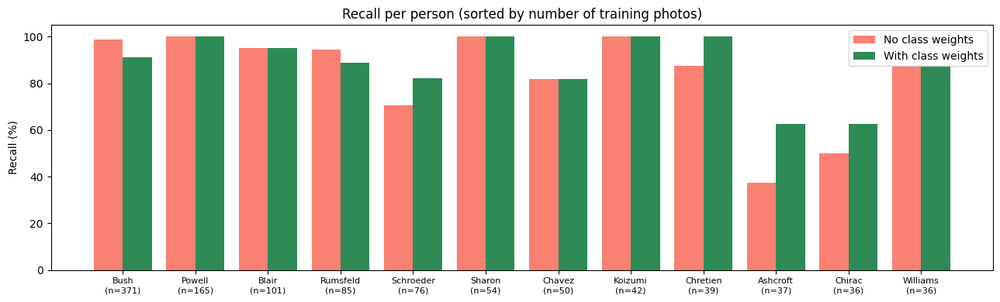

George W Bush recall: 98.8% -> 91.2%
Average recall of the other 11 people: 82.2% -> 87.3%


In [ ]:
# ============================================================
# 22. PER-PERSON RECALL WITH AND WITHOUT CLASS WEIGHTS
# ============================================================

def mean_recall(run_list):
    return np.mean([recall_score(Y_test, r["test_probs"].argmax(1), labels=np.arange(NUM_CLASSES), average=None)
                    for r in run_list], axis=0)

recall_with, recall_without = mean_recall(runs[MNV2]), mean_recall(runs[NO_CW])
order = np.argsort(-np.bincount(Y_train))
positions = np.arange(NUM_CLASSES)

plt.figure(figsize=(13, 4))
plt.bar(positions - 0.2, recall_without[order] * 100, 0.4, label="No class weights", color="salmon")
plt.bar(positions + 0.2, recall_with[order] * 100, 0.4, label="With class weights", color="seagreen")
plt.xticks(positions, [f"{short_names[i]}\n(n={np.sum(Y_train == i)})" for i in order], fontsize=8)
plt.ylabel("Recall (%)")
plt.title("Recall per person (sorted by number of training photos)")
plt.legend()
plt.tight_layout()
save_show("13_class_weights")

majority, minority = order[0], order[1:]
print(f"{class_names[majority]} recall: {recall_without[majority] * 100:.1f}% -> {recall_with[majority] * 100:.1f}%")
print(f"Average recall of the other 11 people: {recall_without[minority].mean() * 100:.1f}% -> {recall_with[minority].mean() * 100:.1f}%")

### 9.5 Test-Time Augmentation (TTA) and robustness
* **TTA:** predict the original face **and** its mirror image, then average the two predictions. It needs no extra training.
* **Robustness:** a real camera sees dark rooms, blur, noise, low resolution, **sunglasses** and **masks**. We apply these to the test faces and measure the accuracy drop.

Without TTA: accuracy 90.60%   macro F1 0.876
With TTA   : accuracy 91.45%   macro F1 0.889
                        MobileNetV2  Basic CNN
Original                       90.6       89.3
Dark (50%)                     82.9       72.2
Bright (+60)                   79.9       75.6
Blur                           76.5       89.3
Noise                          31.2       81.6
Low resolution (32 px)         61.1       89.3
Sunglasses                     40.6       54.7
Face mask                      59.0       62.0


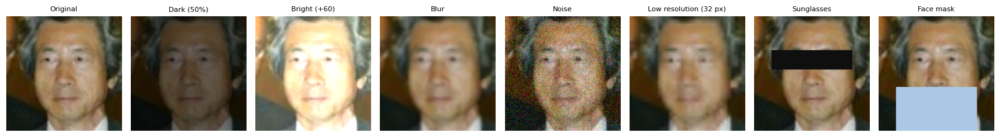

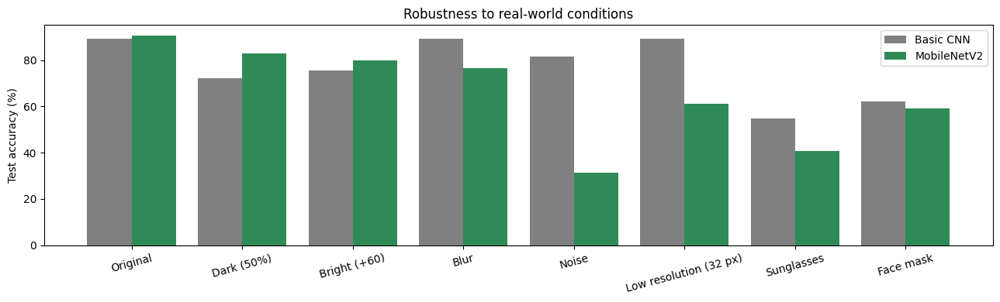

In [ ]:
# ============================================================
# 23. TEST-TIME AUGMENTATION
# ============================================================

flip_probs = mnv2_model.predict(X_test_f[:, :, ::-1, :], verbose=0)
tta_probs = (test_probs + flip_probs) / 2
tta_accuracy = accuracy_score(Y_test, tta_probs.argmax(1))
tta_f1 = f1_score(Y_test, tta_probs.argmax(1), average="macro")
print(f"Without TTA: accuracy {mnv2_accuracy * 100:.2f}%   macro F1 {f1_score(Y_test, predicted_classes, average='macro'):.3f}")
print(f"With TTA   : accuracy {tta_accuracy * 100:.2f}%   macro F1 {tta_f1:.3f}")


# ============================================================
# 24. ROBUSTNESS TEST
# ============================================================

def corrupt(X, kind):
    X = X.astype("float32").copy()
    H = X.shape[1]
    if kind == "Dark (50%)":
        X = X * 0.5
    elif kind == "Bright (+60)":
        X = X * 1.3 + 60
    elif kind == "Blur":
        X = np.array([cv2.GaussianBlur(x, (9, 9), 0) for x in X])
    elif kind == "Noise":
        X = X + np.random.RandomState(SEED).normal(0, 25, X.shape)
    elif kind == "Low resolution (32 px)":
        X = np.array([cv2.resize(cv2.resize(x, (32, 32)), (IMG_SIZE, IMG_SIZE)) for x in X])
    elif kind == "Sunglasses":
        X[:, int(0.30 * H):int(0.47 * H), int(0.15 * H):int(0.85 * H), :] = 15
    elif kind == "Face mask":
        X[:, int(0.62 * H):, int(0.15 * H):int(0.85 * H), :] = [170, 200, 230]
    return np.clip(X, 0, 255)

CORRUPTIONS = ["Original", "Dark (50%)", "Bright (+60)", "Blur", "Noise", "Low resolution (32 px)", "Sunglasses", "Face mask"]
robustness = {"MobileNetV2": [], "Basic CNN": []}
for kind in CORRUPTIONS:
    Xc = corrupt(X_test, kind)
    robustness["MobileNetV2"].append(accuracy_score(Y_test, mnv2_model.predict(Xc, verbose=0).argmax(1)) * 100)
    robustness["Basic CNN"].append(accuracy_score(Y_test, basic_cnn.predict(Xc / 255.0, verbose=0).argmax(1)) * 100)
robustness_table = pd.DataFrame(robustness, index=CORRUPTIONS).round(1)
print(robustness_table)

plt.figure(figsize=(16, 2.6))
for i, kind in enumerate(CORRUPTIONS):
    plt.subplot(1, len(CORRUPTIONS), i + 1)
    plt.imshow(corrupt(X_test[:1], kind)[0].astype("uint8"))
    plt.title(kind, fontsize=8)
    plt.axis("off")
plt.tight_layout()
save_show("14_corruption_examples")

positions = np.arange(len(CORRUPTIONS))
plt.figure(figsize=(13, 4))
plt.bar(positions - 0.2, robustness["Basic CNN"], 0.4, label="Basic CNN", color="gray")
plt.bar(positions + 0.2, robustness["MobileNetV2"], 0.4, label="MobileNetV2", color="seagreen")
plt.xticks(positions, CORRUPTIONS, rotation=15)
plt.ylabel("Test accuracy (%)")
plt.title("Robustness to real-world conditions")
plt.legend()
plt.tight_layout()
save_show("15_robustness")

### 9.6 Does the face detector affect recognition?
We re-crop the raw **test photos** three ways and measure MobileNetV2 accuracy: Haar (as in training), raw YuNet boxes, and calibrated YuNet boxes.

In [ ]:
# ============================================================
# 25. DETECTOR IMPACT ON RECOGNITION
# ============================================================

crop_results = {}
if yunet is not None:
    def crops_with(detector):
        crops = []
        for i in test_idx:
            boxes = detector(images[i])
            crops.append(crop_face(images[i], central_box(boxes, images[i].shape) if boxes else FALLBACK_BOX))
        return np.array(crops, dtype="float32")

    for name, detector in [("Haar (same as training)", detect_faces),
                           ("YuNet – raw boxes", detect_faces_yunet),
                           ("YuNet – calibrated boxes", lambda im: [calibrate_box(b) for b in detect_faces_yunet(im)])]:
        crop_results[name] = accuracy_score(Y_test, mnv2_model.predict(crops_with(detector), verbose=0).argmax(1)) * 100
    for name, acc in crop_results.items():
        print(f"{name:28s} test accuracy {acc:.1f}%")
else:
    print("YuNet not available – skipped.")

Haar (same as training)      test accuracy 90.6%
YuNet – raw boxes            test accuracy 88.9%
YuNet – calibrated boxes     test accuracy 88.5%


## 10. Grad-CAM – where does the model look?
1. Take the feature maps of a late convolution layer (`block_13_expand_relu`, 10×10).
2. Compute the gradient of the predicted person's score with respect to these maps.
3. Average the gradients per map → importance weights → weighted sum → keep positive values → heatmap.

A good face model should focus on the **eyes, nose, mouth and face shape**, not on the background or clothes.

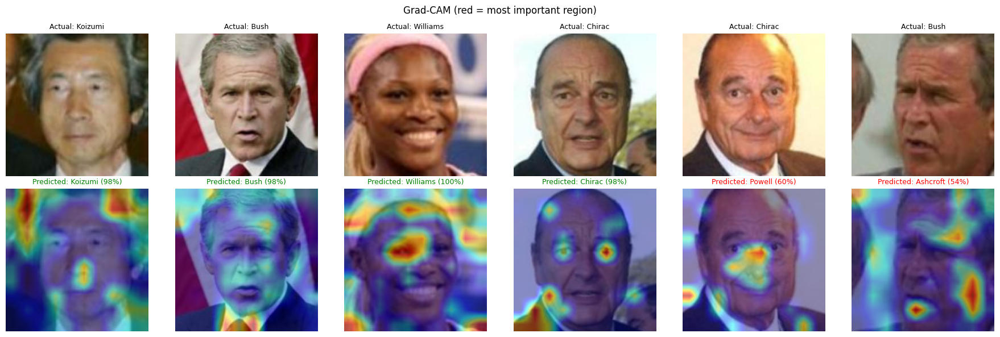

In [ ]:
# ============================================================
# 26. GRAD-CAM
# ============================================================

cam_layer = mnv2_base.get_layer("block_13_expand_relu")
cam_model = keras.Model(mnv2_base.inputs, [cam_layer.output, mnv2_base.output])
rescale_layer = mnv2_model.get_layer("rescale")
head_layers = [mnv2_model.get_layer("gap"), mnv2_model.get_layer("embedding"), mnv2_model.get_layer("classifier")]


def grad_cam(face):
    x = rescale_layer(tf.convert_to_tensor(face[np.newaxis].astype("float32")))
    with tf.GradientTape() as tape:
        conv_output, features = cam_model(x, training=False)
        for layer in head_layers:                      # dropout is off at prediction time, so it is skipped
            features = layer(features)
        predicted = int(tf.argmax(features[0]))
        score = features[:, predicted]
    gradients = tape.gradient(score, conv_output)
    weights = tf.reduce_mean(gradients, axis=(1, 2))
    cam = tf.nn.relu(tf.reduce_sum(conv_output[0] * weights[0], axis=-1)).numpy()
    cam = cv2.resize(cam / (cam.max() + 1e-8), (IMG_SIZE, IMG_SIZE))
    return cam, predicted, float(features[0, predicted])


def overlay_heatmap(face, cam):
    heatmap = cv2.cvtColor(cv2.applyColorMap(np.uint8(255 * cam), cv2.COLORMAP_JET), cv2.COLOR_BGR2RGB)
    return np.uint8(0.55 * face + 0.45 * heatmap)


examples = list(correct_indices[:4]) + list(incorrect_indices[:2])
plt.figure(figsize=(3 * len(examples), 6))
for i, index in enumerate(examples):
    cam, predicted, confidence = grad_cam(X_test[index])
    plt.subplot(2, len(examples), i + 1)
    plt.imshow(X_test[index])
    plt.title("Actual: " + short_names[Y_test[index]], fontsize=9)
    plt.axis("off")
    plt.subplot(2, len(examples), len(examples) + i + 1)
    plt.imshow(overlay_heatmap(X_test[index], cam))
    plt.title(f"Predicted: {short_names[predicted]} ({confidence * 100:.0f}%)",
              color="green" if predicted == Y_test[index] else "red", fontsize=9)
    plt.axis("off")
plt.suptitle("Grad-CAM (red = most important region)")
plt.tight_layout()
save_show("16_gradcam")

## 11. Face Embeddings and t-SNE
We cut the network at the **embedding** layer: every face becomes **256 numbers** (a "face fingerprint"). After L2-normalisation, two faces are compared with **cosine similarity**.
For every person we store the **centroid** (the average embedding of their training photos).

Three embeddings are compared:
* **ImageNet MobileNetV2** – no face training at all (baseline).
* **Softmax embedding** – from our main MobileNetV2.
* **ArcFace embedding** – from the ArcFace model.

**t-SNE** squeezes the 256 numbers to 2 so we can *see* them: each dot is a test face, coloured by person. Good embeddings form tight, separate clusters.

Nearest-centroid test accuracy – ImageNet MobileNetV2 (no face training) : 67.1%
Nearest-centroid test accuracy – Softmax embedding                       : 88.0%
Nearest-centroid test accuracy – ArcFace embedding                       : 89.3%


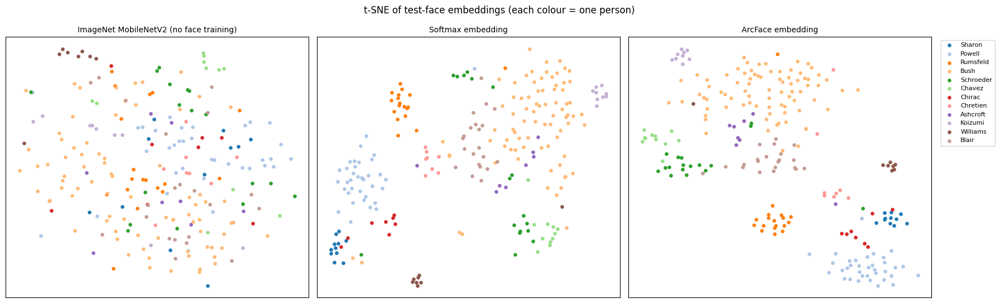

In [ ]:
# ============================================================
# 27. EMBEDDING MODELS
# ============================================================

imagenet_input = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = layers.Rescaling(1.0 / 127.5, offset=-1)(imagenet_input)
x = keras.applications.MobileNetV2(input_shape=(IMG_SIZE, IMG_SIZE, 3), include_top=False,
                                   weights="imagenet", pooling="avg")(x)

def build_embedder(model, base, head):
    """Inference-only model: photo -> rescale -> MobileNetV2 -> pooling -> 256-number embedding.
    (augmentation and dropout are left out because they are only used during training)"""
    face = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    e = model.get_layer("rescale")(face)
    e = base(e, training=False)
    e = model.get_layer("gap")(e)
    if head == "arcface":
        e = model.get_layer("embedding_dense")(e)
    e = model.get_layer("embedding")(e)
    return keras.Model(face, e, name=f"face_embedder_{head}")


IMAGENET_EMB, SOFTMAX_EMB, ARCFACE_EMB = "ImageNet MobileNetV2 (no face training)", "Softmax embedding", "ArcFace embedding"
EMBEDDERS = {
    IMAGENET_EMB: keras.Model(imagenet_input, x),
    SOFTMAX_EMB: build_embedder(mnv2_model, mnv2_base, "softmax"),
    ARCFACE_EMB: build_embedder(arc_model, selected[ARC]["base"], "arcface"),
}


def l2_normalize(E):
    return E / (np.linalg.norm(E, axis=1, keepdims=True) + 1e-10)


def get_embeddings(faces, name=SOFTMAX_EMB):
    """Embeddings in chunks of 256 faces, so thousands of photos never need GBs of RAM at once."""
    outputs = []
    for i in range(0, len(faces), 256):
        chunk = np.asarray(faces[i:i + 256], dtype="float32")
        outputs.append(np.asarray(EMBEDDERS[name](chunk, training=False)))   # direct call: much faster than predict() for a few faces
    return l2_normalize(np.vstack(outputs))


EMB = {name: {"train": get_embeddings(X_train, name), "cal": get_embeddings(X_cal, name),
              "test": get_embeddings(X_test, name)} for name in EMBEDDERS}
CENTROIDS = {name: l2_normalize(np.array([EMB[name]["train"][Y_train == c].mean(axis=0) for c in range(NUM_CLASSES)]))
             for name in EMBEDDERS}

for name in EMBEDDERS:
    acc = np.mean(np.argmax(EMB[name]["test"] @ CENTROIDS[name].T, axis=1) == Y_test)
    print(f"Nearest-centroid test accuracy – {name:40s}: {acc * 100:.1f}%")


# ============================================================
# 28. t-SNE VISUALISATION
# ============================================================

plt.figure(figsize=(18, 5.5))
for k, name in enumerate(EMBEDDERS):
    points = TSNE(n_components=2, perplexity=30, init="pca", random_state=SEED).fit_transform(EMB[name]["test"])
    plt.subplot(1, 3, k + 1)
    for c in range(NUM_CLASSES):
        plt.scatter(points[Y_test == c, 0], points[Y_test == c, 1], s=14, label=short_names[c], color=plt.cm.tab20(c))
    plt.title(name, fontsize=10)
    plt.xticks([])
    plt.yticks([])
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.suptitle("t-SNE of test-face embeddings (each colour = one person)")
plt.tight_layout()
save_show("17_tsne")

## 12. Strangers and New People (from the rest of LFW)
* **800 strangers** (people with < 10 photos, one photo each): 400 for **calibration** and 400 different ones for **testing**.
* **People with ≥ 15 photos:** 10 are used as **new people to enroll**, the rest for **verification**.

None of these people were used in training.

In [ ]:
# ============================================================
# 29. LOAD STRANGERS AND NEW PEOPLE
# ============================================================

# LFW_FOLDER was found in Section 2 (works for every download source)
all_people = {}
for person in sorted(os.listdir(LFW_FOLDER)):
    folder = os.path.join(LFW_FOLDER, person)
    if os.path.isdir(folder):
        files = sorted(f for f in os.listdir(folder) if f.endswith(".jpg"))
        all_people[person.replace("_", " ")] = [os.path.join(folder, f) for f in files]
unknown_people = {n: f for n, f in all_people.items() if n not in class_names and f}
print("People not in the training set:", len(unknown_people))


def read_image(path):
    return cv2.cvtColor(cv2.imread(path), cv2.COLOR_BGR2RGB)


def load_faces(paths):
    return np.array([get_face(read_image(p))[0] for p in paths], dtype="uint8")


rng = np.random.RandomState(SEED)
few_photo_people = [n for n in sorted(unknown_people) if len(unknown_people[n]) < 10]
rng.shuffle(few_photo_people)
stranger_cal_paths = [unknown_people[n][0] for n in few_photo_people[:400]]
stranger_test_paths = [unknown_people[n][0] for n in few_photo_people[400:800]]
strangers_cal, strangers_test = load_faces(stranger_cal_paths), load_faces(stranger_test_paths)

many_photo_people = [n for n in sorted(unknown_people) if len(unknown_people[n]) >= 15]
new_people = [str(n) for n in rng.choice(many_photo_people, 10, replace=False)]
verify_people = [n for n in many_photo_people if n not in new_people]
new_faces = {n: load_faces(unknown_people[n][:20]) for n in new_people}

print("Strangers (calibration / test):", len(strangers_cal), "/", len(strangers_test))
print("New people to enroll           :", new_people)
print("People for verification        :", len(verify_people))

People not in the training set: 5737
Strangers (calibration / test): 400 / 400
New people to enroll           : ['Vicente Fox', 'Michael Bloomberg', 'Jennifer Capriati', 'Bill Gates', 'Mahmoud Abbas', 'Pete Sampras', 'Tom Daschle', 'Igor Ivanov', 'Fidel Castro', 'Atal Bihari Vajpayee']
People for verification        : 74


## 13. Unknown Person Detection (open-set recognition)
A softmax classifier **always** names one of the 12 people, even for a stranger. We compare three scores for saying **"Unknown"**:
1. **Max softmax probability** (the classifier's confidence).
2. **Cosine similarity to the nearest centroid** – softmax embedding.
3. **Cosine similarity to the nearest centroid** – ArcFace embedding.

* **AUC** – how well the score separates known people from strangers (1 = perfect, 0.5 = random).
* **Known correct** – known faces accepted **and** named correctly.
* **FAR (False Acceptance Rate)** – strangers wrongly accepted. **This is the security number.**
* The threshold is chosen on the **calibration** split (calibration faces + 400 calibration strangers) and reported on the **test** split (test faces + 400 different strangers).

                                   Score   AUC  Threshold  Known correct (%)  Strangers accepted – FAR (%)
                 Max softmax probability 0.803      0.838               67.1                          21.2
              Cosine – Softmax embedding 0.871      0.836               71.4                          16.5
              Cosine – ArcFace embedding 0.876      0.684               74.8                          14.0
Max softmax, fixed 60% (common shortcut)   NaN      0.600               84.6                          54.2

Embedding used by the final system: ArcFace embedding


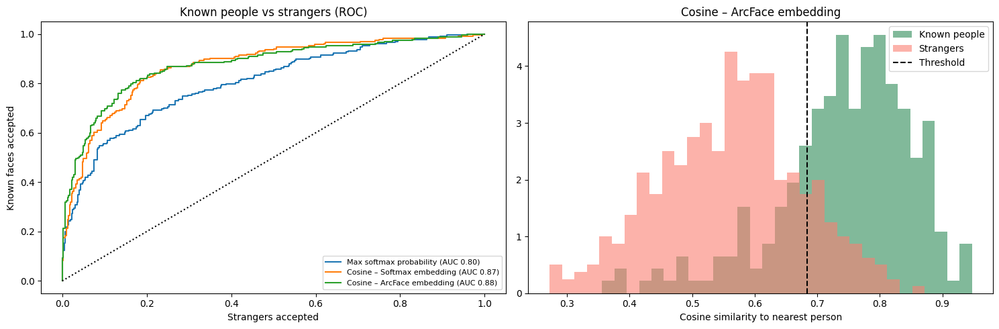

In [ ]:
# ============================================================
# 30. OPEN-SET EVALUATION
# ============================================================

def evaluate_threshold(t, known_scores, known_predicted, known_true, stranger_scores):
    known_correct = np.mean((known_scores >= t) & (known_predicted == known_true))
    false_accept = np.mean(stranger_scores >= t)
    return known_correct, false_accept


def choose_threshold(known_scores, known_predicted, known_true, stranger_scores):
    best_t, best_value = 0.0, -1
    for t in np.unique(np.concatenate([known_scores, stranger_scores])):
        known_correct, false_accept = evaluate_threshold(t, known_scores, known_predicted, known_true, stranger_scores)
        value = (known_correct + 1 - false_accept) / 2
        if value > best_value:
            best_t, best_value = float(t), value
    return best_t, best_value


SCORERS = {}
probs_cal, probs_ucal = mnv2_model.predict(X_cal_f, verbose=0), mnv2_model.predict(strangers_cal.astype("float32"), verbose=0)
probs_test, probs_utest = test_probs, mnv2_model.predict(strangers_test.astype("float32"), verbose=0)
SCORERS["Max softmax probability"] = {"cal": (probs_cal.max(1), probs_cal.argmax(1)), "unk_cal": probs_ucal.max(1),
                                      "test": (probs_test.max(1), probs_test.argmax(1)), "unk_test": probs_utest.max(1)}
for name in [SOFTMAX_EMB, ARCFACE_EMB]:
    S = {"cal": EMB[name]["cal"] @ CENTROIDS[name].T, "test": EMB[name]["test"] @ CENTROIDS[name].T,
         "unk_cal": get_embeddings(strangers_cal, name) @ CENTROIDS[name].T,
         "unk_test": get_embeddings(strangers_test, name) @ CENTROIDS[name].T}
    SCORERS["Cosine – " + name] = {"cal": (S["cal"].max(1), S["cal"].argmax(1)), "unk_cal": S["unk_cal"].max(1),
                                   "test": (S["test"].max(1), S["test"].argmax(1)), "unk_test": S["unk_test"].max(1)}

OPEN_SET, rows = {}, []
for name, s in SCORERS.items():
    t, cal_value = choose_threshold(*s["cal"], Y_cal, s["unk_cal"])            # chosen on CALIBRATION data
    known_correct, far = evaluate_threshold(t, *s["test"], Y_test, s["unk_test"])   # reported on TEST data
    auc = roc_auc_score(np.r_[np.ones(len(s["test"][0])), np.zeros(len(s["unk_test"]))], np.r_[s["test"][0], s["unk_test"]])
    OPEN_SET[name] = dict(threshold=t, cal_value=cal_value, known_correct=known_correct, far=far, auc=auc)
    rows.append({"Score": name, "AUC": round(auc, 3), "Threshold": round(t, 3),
                 "Known correct (%)": round(known_correct * 100, 1), "Strangers accepted – FAR (%)": round(far * 100, 1)})
known_60, far_60 = evaluate_threshold(0.60, *SCORERS["Max softmax probability"]["test"], Y_test,
                                      SCORERS["Max softmax probability"]["unk_test"])
rows.append({"Score": "Max softmax, fixed 60% (common shortcut)", "AUC": None, "Threshold": 0.60,
             "Known correct (%)": round(known_60 * 100, 1), "Strangers accepted – FAR (%)": round(far_60 * 100, 1)})
open_set_table = pd.DataFrame(rows)
print(open_set_table.to_string(index=False))

EMBEDDING_SCORERS = ["Cosine – " + SOFTMAX_EMB, "Cosine – " + ARCFACE_EMB]
BEST_SCORER = max(EMBEDDING_SCORERS, key=lambda n: OPEN_SET[n]["cal_value"])     # chosen on calibration data
PIPELINE_EMB = BEST_SCORER.replace("Cosine – ", "")
print("\nEmbedding used by the final system:", PIPELINE_EMB)

plt.figure(figsize=(15, 5))
plt.subplot(1, 2, 1)
for name, s in SCORERS.items():
    fpr, tpr, _ = roc_curve(np.r_[np.ones(len(s["test"][0])), np.zeros(len(s["unk_test"]))], np.r_[s["test"][0], s["unk_test"]])
    plt.plot(fpr, tpr, label=f"{name} (AUC {OPEN_SET[name]['auc']:.2f})")
plt.plot([0, 1], [0, 1], "k:")
plt.xlabel("Strangers accepted")
plt.ylabel("Known faces accepted")
plt.title("Known people vs strangers (ROC)")
plt.legend(fontsize=8)
plt.subplot(1, 2, 2)
s = SCORERS[BEST_SCORER]
plt.hist(s["test"][0], bins=30, alpha=0.6, density=True, label="Known people", color="seagreen")
plt.hist(s["unk_test"], bins=30, alpha=0.6, density=True, label="Strangers", color="salmon")
plt.axvline(OPEN_SET[BEST_SCORER]["threshold"], color="black", linestyle="--", label="Threshold")
plt.title(BEST_SCORER)
plt.xlabel("Cosine similarity to nearest person")
plt.legend()
plt.tight_layout()
save_show("18_unknown_detection")

## 14. Adding New People WITHOUT Retraining
A softmax classifier must be **retrained** to add a 13th person. With embeddings we only need **K photos**: average their embeddings into a centroid and add it to the gallery.

**Experiment:** enroll the 10 new people with K = 1, 3, 5 or 10 photos each, then recognise their *other* photos among all 22 people (5 random repeats). We also check the original 12 people are still recognised.

                                        K=1 new people (%) K=3 new people (%) K=5 new people (%) K=10 new people (%) Original 12 people, K=5 (%)
ImageNet MobileNetV2 (no face training)          3.1 ± 1.3         17.3 ± 2.4         29.7 ± 1.6          44.8 ± 2.9                        63.5
Softmax embedding                               10.3 ± 3.7         28.2 ± 3.4         35.4 ± 4.6          45.7 ± 2.2                        83.1
ArcFace embedding                               13.9 ± 2.8         25.7 ± 1.1         32.3 ± 3.5          40.2 ± 3.7                        85.8


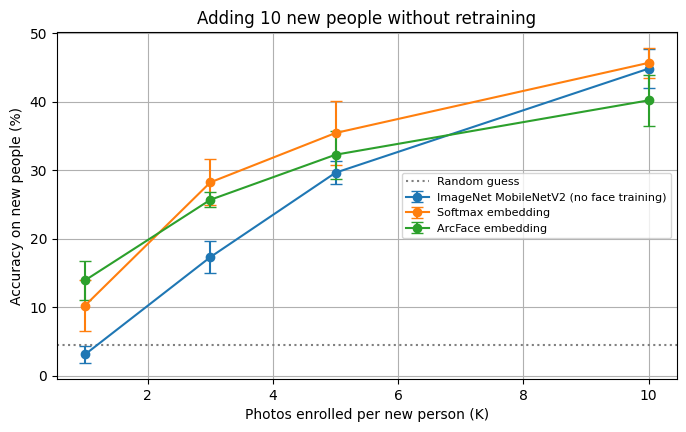

In [ ]:
# ============================================================
# 31. ENROLLMENT EXPERIMENT
# ============================================================

new_embeddings = {name: {n: get_embeddings(new_faces[n], name) for n in new_people} for name in EMBEDDERS}
enroll_results = {}
for name in EMBEDDERS:
    enroll_results[name] = {}
    for K in [1, 3, 5, 10]:
        new_acc, known_acc = [], []
        for trial in range(5):
            r = np.random.RandomState(100 + trial)
            new_centroids, query_E, query_Y = [], [], []
            for j, n in enumerate(new_people):
                E = new_embeddings[name][n]
                order = r.permutation(len(E))
                new_centroids.append(E[order[:K]].mean(axis=0))
                query_E.append(E[order[K:]])
                query_Y += [NUM_CLASSES + j] * (len(E) - K)
            all_centroids = l2_normalize(np.vstack([CENTROIDS[name], np.array(new_centroids)]))
            new_acc.append(np.mean(np.argmax(np.vstack(query_E) @ all_centroids.T, axis=1) == np.array(query_Y)))
            known_acc.append(np.mean(np.argmax(EMB[name]["test"] @ all_centroids.T, axis=1) == Y_test))
        enroll_results[name][K] = (np.mean(new_acc), np.std(new_acc), np.mean(known_acc))

enroll_table = pd.DataFrame({name: {f"K={K} new people (%)": f"{v[K][0] * 100:.1f} ± {v[K][1] * 100:.1f}" for K in v}
                             for name, v in enroll_results.items()}).T
enroll_table["Original 12 people, K=5 (%)"] = [f"{enroll_results[n][5][2] * 100:.1f}" for n in EMBEDDERS]
print(enroll_table.to_string())

plt.figure(figsize=(8, 4.5))
for name, v in enroll_results.items():
    Ks = list(v)
    plt.errorbar(Ks, [v[k][0] * 100 for k in Ks], yerr=[v[k][1] * 100 for k in Ks], marker="o", capsize=4, label=name)
plt.axhline(100 / 22, color="gray", linestyle=":", label="Random guess")
plt.xlabel("Photos enrolled per new person (K)")
plt.ylabel("Accuracy on new people (%)")
plt.title("Adding 10 new people without retraining")
plt.legend(fontsize=8)
plt.grid()
save_show("19_enrollment")

## 15. Face Verification – "Are these two photos the same person?"

### 15.1 Unseen people
1,500 **same-person** pairs and 1,500 **different-person** pairs, all from people never used in training.
* **AUC** – area under the ROC curve. **EER** – where false accepts = false rejects (lower is better).
* **TAR @ FAR 1%** – same-person pairs accepted when only 1% of impostors get through.
* **10-fold accuracy** – the LFW standard: choose the threshold on 9 folds, test on the 10th.

### 15.2 The official LFW benchmark (View 2, 6,000 pairs, 10 fixed folds)
Published systems report this number (FaceNet 99.63%). The official pairs include our 12 training people, which would make our numbers optimistic, so we report **all pairs** *and* **unseen people only**.

740 photos of 74 unseen people, 3000 pairs

                                           AUC EER (%) TAR @ FAR 1% (%) 10-fold accuracy (%)
ImageNet MobileNetV2 (no face training)  0.754    30.4             11.5           70.0 ± 1.3
Softmax embedding                         0.84    23.6             20.9           76.0 ± 1.5
ArcFace embedding                        0.811    26.9             18.0           73.1 ± 1.6

Verification threshold used in the GUI (EER point, ArcFace embedding): 0.263


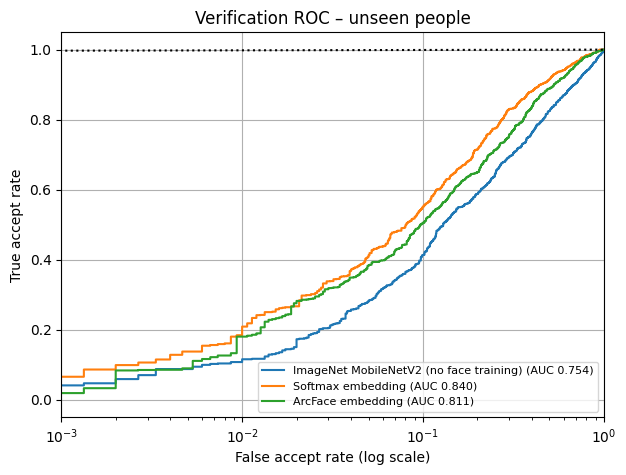

In [ ]:
# ============================================================
# 32. VERIFICATION ON UNSEEN PEOPLE
# ============================================================

def best_threshold(similarities, labels):
    candidates = np.quantile(similarities, np.linspace(0, 1, 400))
    return max(candidates, key=lambda c: np.mean((similarities >= c) == labels))


def verification_metrics(similarities, labels, folds=None):
    fpr, tpr, thresholds = roc_curve(labels, similarities)
    k = int(np.nanargmin(np.abs(fpr - (1 - tpr))))
    if folds is None:
        splits = list(KFold(10, shuffle=True, random_state=SEED).split(similarities))
    else:
        splits = [(np.where(folds != f)[0], np.where(folds == f)[0]) for f in np.unique(folds)]
    accuracies = [np.mean((similarities[te] >= best_threshold(similarities[tr], labels[tr])) == labels[te]) for tr, te in splits]
    return {"auc": roc_auc_score(labels, similarities), "eer": (fpr[k] + 1 - tpr[k]) / 2,
            "eer_threshold": float(min(thresholds[k], 1.0)), "tar_far1": float(np.interp(0.01, fpr, tpr)),
            "acc": np.mean(accuracies), "acc_std": np.std(accuracies), "fpr": fpr, "tpr": tpr}


verify_faces, verify_ids = [], []
for i, n in enumerate(verify_people):
    for path in unknown_people[n][:10]:
        verify_faces.append(get_face(read_image(path))[0])
        verify_ids.append(i)
verify_faces, verify_ids = np.array(verify_faces), np.array(verify_ids)

pairs, pair_labels = [], []
while len(pairs) < 1500:
    idx = np.where(verify_ids == rng.randint(len(verify_people)))[0]
    if len(idx) >= 2:
        a, b = rng.choice(idx, 2, replace=False)
        pairs.append((a, b)); pair_labels.append(1)
while len(pairs) < 3000:
    a, b = rng.randint(len(verify_ids), size=2)
    if verify_ids[a] != verify_ids[b]:
        pairs.append((a, b)); pair_labels.append(0)
pairs, pair_labels = np.array(pairs), np.array(pair_labels)

VERIFICATION = {}
for name in EMBEDDERS:
    E = get_embeddings(verify_faces, name)
    VERIFICATION[name] = verification_metrics(np.sum(E[pairs[:, 0]] * E[pairs[:, 1]], axis=1), pair_labels)
verification_table = pd.DataFrame({n: {"AUC": round(v["auc"], 3), "EER (%)": round(v["eer"] * 100, 1),
                                       "TAR @ FAR 1% (%)": round(v["tar_far1"] * 100, 1),
                                       "10-fold accuracy (%)": f"{v['acc'] * 100:.1f} ± {v['acc_std'] * 100:.1f}"}
                                   for n, v in VERIFICATION.items()}).T
print(f"{len(verify_faces)} photos of {len(verify_people)} unseen people, {len(pairs)} pairs\n")
print(verification_table.to_string())
VERIFY_THRESHOLD = VERIFICATION[PIPELINE_EMB]["eer_threshold"]
print(f"\nVerification threshold used in the GUI (EER point, {PIPELINE_EMB}): {VERIFY_THRESHOLD:.3f}")

plt.figure(figsize=(7, 5))
for n, v in VERIFICATION.items():
    plt.plot(v["fpr"], v["tpr"], label=f"{n} (AUC {v['auc']:.3f})")
plt.plot([0, 1], [0, 1], "k:")
plt.xscale("log")
plt.xlim(1e-3, 1)
plt.xlabel("False accept rate (log scale)")
plt.ylabel("True accept rate")
plt.title("Verification ROC – unseen people")
plt.legend(fontsize=8)
plt.grid()
save_show("20_verification_roc")

In [ ]:
# ============================================================
# 33. OFFICIAL LFW BENCHMARK (pairs.txt, 10 folds)
# ============================================================

OFFICIAL = {}
gc.collect()
try:
    pairs_file = os.path.join(LFW_HOME, "pairs.txt")
    saved_pairs = os.path.join(SAVE_DIR, "pairs.txt")
    if not os.path.exists(pairs_file) and os.path.exists(saved_pairs):
        shutil.copy(saved_pairs, pairs_file)                                 # copy kept in Google Drive
    os.makedirs(LFW_HOME, exist_ok=True)
    if not os.path.exists(pairs_file):
        try:
            from sklearn.datasets import fetch_lfw_pairs
            fetch_lfw_pairs(subset="10_folds", resize=0.1, color=False)     # only to download pairs.txt
        except Exception as e:
            print("scikit-learn pairs download failed:", e, "-> trying the LFW website")
            urllib.request.urlretrieve("http://vis-www.cs.umass.edu/lfw/pairs.txt", pairs_file)
    if not os.path.exists(saved_pairs):
        shutil.copy(pairs_file, saved_pairs)
    with open(pairs_file) as f:
        lines = [line.split() for line in f if line.strip()]
    n_folds, n_per_fold = int(lines[0][0]), int(lines[0][1])
    official_pairs = []
    for fold in range(n_folds):
        for p in lines[1 + fold * 2 * n_per_fold: 1 + (fold + 1) * 2 * n_per_fold]:
            if len(p) == 3:
                official_pairs.append((fold, (p[0], int(p[1])), (p[0], int(p[2])), 1))
            else:
                official_pairs.append((fold, (p[0], int(p[1])), (p[2], int(p[3])), 0))

    keys = sorted({k for _, a, b, _ in official_pairs for k in (a, b)})
    key_index = {k: i for i, k in enumerate(keys)}
    official_faces = load_faces([os.path.join(LFW_FOLDER, n, f"{n}_{i:04d}.jpg") for n, i in keys])
    folds = np.array([p[0] for p in official_pairs])
    labels = np.array([p[3] for p in official_pairs])
    ia = np.array([key_index[p[1]] for p in official_pairs])
    ib = np.array([key_index[p[2]] for p in official_pairs])
    seen = np.array([p[1][0].replace("_", " ") in class_names or p[2][0].replace("_", " ") in class_names
                     for p in official_pairs])
    print(f"{len(official_pairs)} official pairs; {seen.sum()} involve one of our 12 training people")

    for name in EMBEDDERS:
        E = get_embeddings(official_faces, name)
        similarity = np.sum(E[ia] * E[ib], axis=1)
        OFFICIAL[name] = {"All 6,000 pairs": verification_metrics(similarity, labels, folds)["acc"],
                          "Unseen people only": verification_metrics(similarity[~seen], labels[~seen], folds[~seen])["acc"]}
    official_table = (pd.DataFrame(OFFICIAL).T * 100).round(1)
    print(official_table.to_string())
    print("\nFor reference (trained on millions of faces): FaceNet 99.63%, ArcFace 99.83%. Humans ≈ 97.5%.")
    del official_faces
except Exception as e:
    print("Official LFW benchmark skipped:", type(e).__name__, e)

6000 official pairs; 60 involve one of our 12 training people
                                         All 6,000 pairs  Unseen people only
ImageNet MobileNetV2 (no face training)             71.7                71.7
Softmax embedding                                   76.0                75.9
ArcFace embedding                                   73.8                73.6

For reference (trained on millions of faces): FaceNet 99.63%, ArcFace 99.83%. Humans ≈ 97.5%.


## 16. Deployment – Speed, Size and TensorFlow Lite
* **Latency** is measured for **one image at a time** (what a user really waits for), median of 50 runs.
* **TensorFlow Lite** with 8-bit weight quantisation stores weights as integers instead of 32-bit floats → ~4× smaller for phones / Raspberry Pi. We check that accuracy is kept.

In [ ]:
# ============================================================
# 34. LATENCY
# ============================================================

def median_ms(function, runs=50):
    for _ in range(5):
        function()
    times = []
    for _ in range(runs):
        start = time.perf_counter()
        function()
        times.append(time.perf_counter() - start)
    return float(np.median(times) * 1000)

one_face = tf.constant(X_test_f[:1])
latency_table = pd.DataFrame({
    "Parameters": [f"{basic_cnn.count_params():,}", f"{vgg_model.count_params():,}", f"{mnv2_model.count_params():,}"],
    "Size (MB)": [round(m.count_params() * 4 / 1e6, 1) for m in (basic_cnn, vgg_model, mnv2_model)],
    "Latency (ms / face)": [round(median_ms(lambda: basic_cnn(one_face / 255.0, training=False)), 2),
                            round(median_ms(lambda: vgg_model(tf.constant(X_test_vgg[:1]), training=False)), 2),
                            round(median_ms(lambda: mnv2_model(one_face, training=False)), 2)],
}, index=["Basic CNN", "VGG16", "MobileNetV2"])
haar_latency = median_ms(lambda: detect_faces(images[0]))
print(latency_table)
print(f"\nHaar detection: {haar_latency:.1f} ms per photo")
print(f"Full pipeline (Haar + MobileNetV2): ~{haar_latency + latency_table.loc['MobileNetV2', 'Latency (ms / face)']:.1f} ms "
      f"-> ~{1000 / (haar_latency + latency_table.loc['MobileNetV2', 'Latency (ms / face)']):.0f} frames per second")


# ============================================================
# 35. TENSORFLOW LITE EXPORT
# ============================================================

# Inference-only copy (no augmentation / dropout layers)
inference_input = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
z = mnv2_model.get_layer("rescale")(inference_input)
z = mnv2_base(z, training=False)
z = mnv2_model.get_layer("gap")(z)
z = mnv2_model.get_layer("embedding")(z)
inference_model = keras.Model(inference_input, mnv2_model.get_layer("classifier")(z))

TFLITE = {}
tflite_bytes = None
for method in ["keras", "saved_model"]:
    try:
        if method == "keras":
            converter = tf.lite.TFLiteConverter.from_keras_model(inference_model)
        else:
            inference_model.export("inference_savedmodel")
            converter = tf.lite.TFLiteConverter.from_saved_model("inference_savedmodel")
        converter.optimizations = [tf.lite.Optimize.DEFAULT]
        tflite_bytes = converter.convert()
        break
    except Exception as e:
        print(f"TFLite conversion ({method}) failed: {type(e).__name__}: {str(e)[:120]}")

if tflite_bytes:
    with open("face_recognition_int8.tflite", "wb") as f:
        f.write(tflite_bytes)
    inference_model.save("face_recognition_fp32.keras")
    interpreter = tf.lite.Interpreter(model_content=tflite_bytes)
    interpreter.allocate_tensors()
    input_details, output_details = interpreter.get_input_details()[0], interpreter.get_output_details()[0]

    def tflite_predict(face):
        interpreter.set_tensor(input_details["index"], face[np.newaxis].astype("float32"))
        interpreter.invoke()
        return interpreter.get_tensor(output_details["index"])[0]

    tflite_pred = np.array([tflite_predict(f).argmax() for f in X_test_f])
    TFLITE = {"Keras FP32 size (MB)": round(os.path.getsize("face_recognition_fp32.keras") / 1e6, 1),
              "TFLite INT8 size (MB)": round(len(tflite_bytes) / 1e6, 1),
              "Keras accuracy (%)": round(mnv2_accuracy * 100, 2),
              "TFLite accuracy (%)": round(accuracy_score(Y_test, tflite_pred) * 100, 2),
              "Same prediction (%)": round(np.mean(tflite_pred == predicted_classes) * 100, 1)}
    for k, v in TFLITE.items():
        print(f"{k:24s}: {v}")

             Parameters  Size (MB)  Latency (ms / face)
Basic CNN     2,963,244       11.9                 7.83
VGG16        17,994,828       72.0                29.79
MobileNetV2   2,589,004       10.4               164.13

Haar detection: 21.1 ms per photo
Full pipeline (Haar + MobileNetV2): ~185.2 ms -> ~5 frames per second
Saved artifact at '/tmp/tmpy_fqvp3n'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 160, 160, 3), dtype=tf.float32, name='keras_tensor_3512')
Output Type:
  TensorSpec(shape=(None, 12), dtype=tf.float32, name=None)
Captures:
  139898052361488: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139898036577360: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139898036571408: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139898036577168: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139898036576784: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139898164958928: TensorSpec(s

## 17. The Complete System – Detect → Recognize → Unknown → Enroll
The final system keeps a **gallery** (one centroid per person) using the embedding chosen in Section 13.
* `recognize_faces(photo)` – finds every face, names it or says **"Unknown"**.
* `enroll_person(name, faces)` – adds a person instantly. `remove_person(name)` – deletes them.

Embedding: ArcFace embedding | Unknown threshold: 0.684 | Verify threshold: 0.263


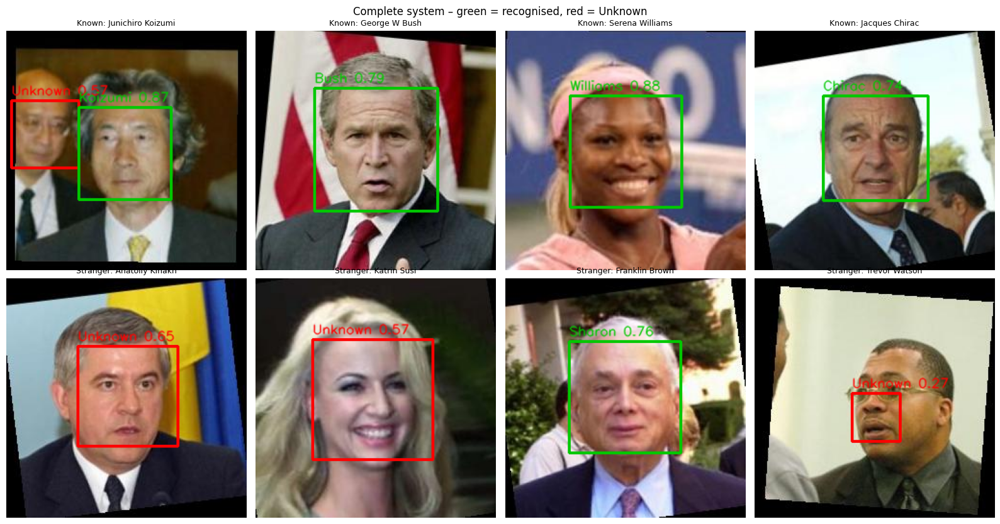

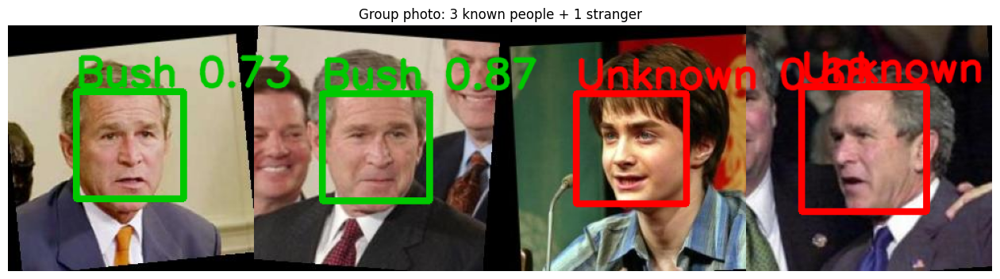

George W Bush                similarity 0.728
George W Bush                similarity 0.868
Unknown                      similarity 0.681
Unknown                      similarity 0.508


In [ ]:
# ============================================================
# 36. GALLERY AND RECOGNITION FUNCTIONS
# ============================================================

gallery_names = list(class_names)
gallery_source = ["trained (LFW)"] * NUM_CLASSES
gallery_centroids = CENTROIDS[PIPELINE_EMB].copy()
ENROLLED_FACES = {}                # name -> face crops of people YOU enrolled (so they can be restored later)
UNKNOWN_THRESHOLD = OPEN_SET[BEST_SCORER]["threshold"]
GALLERY_FILE = os.path.join(SAVE_DIR, "gallery.npz")
ENROLLED_FILE = os.path.join(SAVE_DIR, "enrolled_faces.npz")
print(f"Embedding: {PIPELINE_EMB} | Unknown threshold: {UNKNOWN_THRESHOLD:.3f} | Verify threshold: {VERIFY_THRESHOLD:.3f}")


def enroll_person(name, faces):
    global gallery_centroids
    faces = np.asarray(faces, dtype="uint8")
    centroid = l2_normalize(get_embeddings(faces, PIPELINE_EMB).mean(axis=0, keepdims=True))[0]
    source = f"enrolled ({len(faces)} photos)"
    if name in gallery_names:
        k = gallery_names.index(name)
        gallery_centroids[k], gallery_source[k] = centroid, source
    else:
        gallery_names.append(name)
        gallery_source.append(source)
        gallery_centroids = np.vstack([gallery_centroids, centroid])
    ENROLLED_FACES[name] = faces


def remove_person(name):
    global gallery_centroids
    if name not in gallery_names:
        return False
    k = gallery_names.index(name)
    del gallery_names[k], gallery_source[k]
    gallery_centroids = np.delete(gallery_centroids, k, axis=0)
    ENROLLED_FACES.pop(name, None)
    return True


def save_gallery():
    """Saves the gallery + enrolled face crops (to Google Drive if it is connected)."""
    np.savez(GALLERY_FILE, names=np.array(gallery_names), source=np.array(gallery_source),
             centroids=gallery_centroids, threshold=UNKNOWN_THRESHOLD)
    names = list(ENROLLED_FACES)
    np.savez(ENROLLED_FILE, names=np.array(names, dtype=str),
             **{f"face_{i}": ENROLLED_FACES[n] for i, n in enumerate(names)})


def restore_enrolled_people():
    """Re-enrolls people saved in an earlier session, using THIS run's model (works even after retraining)."""
    if not os.path.exists(ENROLLED_FILE):
        return []
    data = np.load(ENROLLED_FILE, allow_pickle=False)
    restored = []
    for i, name in enumerate(data["names"]):
        enroll_person(str(name), data[f"face_{i}"])
        restored.append(str(name))
    return restored


def identify(faces, threshold=None):
    threshold = UNKNOWN_THRESHOLD if threshold is None else threshold
    S = get_embeddings(faces, PIPELINE_EMB) @ gallery_centroids.T
    return [(gallery_names[k] if s >= threshold else "Unknown", float(s)) for k, s in zip(S.argmax(1), S.max(1))]


def recognize_faces(image, threshold=None, detector="haar"):
    """Returns (annotated image, list of (name, similarity, box))."""
    output = image.copy()
    boxes = pipeline_boxes(image, detector)
    if len(boxes) == 0:
        return output, []
    results = identify(np.array([crop_face(image, b) for b in boxes]), threshold)
    thickness = max(1, image.shape[1] // 300)
    found = []
    for (x, y, w, h), (name, score) in zip(boxes, results):
        color = (0, 200, 0) if name != "Unknown" else (255, 0, 0)
        cv2.rectangle(output, (x, y), (x + w, y + h), color, 2 * thickness)
        cv2.putText(output, f"{name.split()[-1]} {score:.2f}", (x, max(15, y - 6)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.45 * thickness, color, thickness, cv2.LINE_AA)
        found.append((name, round(score, 3), (x, y, w, h)))
    return output, found


# ============================================================
# 37. TEST THE COMPLETE SYSTEM
# ============================================================

plt.figure(figsize=(16, 8.5))
for i in range(4):
    output, _ = recognize_faces(images[test_idx[i]])
    plt.subplot(2, 4, i + 1)
    plt.imshow(output)
    plt.title("Known: " + class_names[Y_all[test_idx[i]]], fontsize=9)
    plt.axis("off")
for i in range(4):
    path = stranger_test_paths[i]
    output, _ = recognize_faces(read_image(path))
    plt.subplot(2, 4, 5 + i)
    plt.imshow(output)
    plt.title("Stranger: " + os.path.basename(os.path.dirname(path)).replace("_", " "), fontsize=9)
    plt.axis("off")
plt.suptitle("Complete system – green = recognised, red = Unknown")
plt.tight_layout()
save_show("21_system_demo")

group_photo = np.hstack([images[test_idx[4]], images[test_idx[5]], read_image(stranger_test_paths[4]), images[test_idx[6]]])
output, found = recognize_faces(group_photo)
plt.figure(figsize=(16, 4.5))
plt.imshow(output)
plt.axis("off")
plt.title("Group photo: 3 known people + 1 stranger")
save_show("22_group_photo")
for name, score, box in found:
    print(f"{name:28s} similarity {score:.3f}")

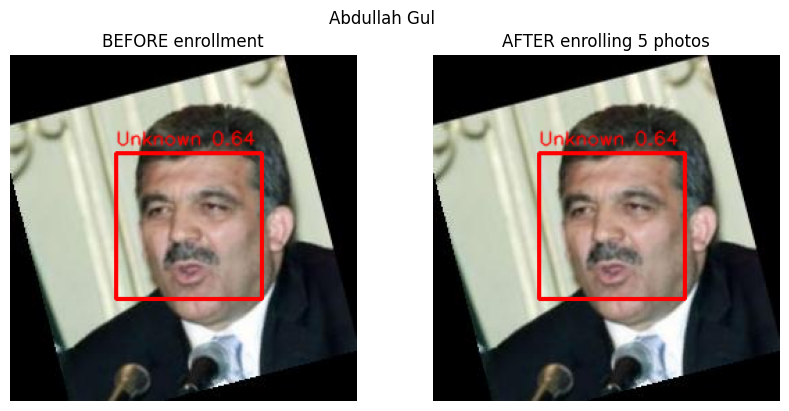

Before: [('Unknown', 0.639, (76, 71, 105, 105))]
After : [('Unknown', 0.639, (76, 71, 105, 105))]


True

In [ ]:
# ============================================================
# 38. LIVE ENROLLMENT DEMO
# ============================================================

demo_person = verify_people[0]
query_image = read_image(unknown_people[demo_person][-1])

before, found_before = recognize_faces(query_image)
enroll_person(demo_person, load_faces(unknown_people[demo_person][:5]))        # 5 photos, no retraining
after, found_after = recognize_faces(query_image)

plt.figure(figsize=(10, 4.5))
plt.subplot(1, 2, 1); plt.imshow(before); plt.title("BEFORE enrollment"); plt.axis("off")
plt.subplot(1, 2, 2); plt.imshow(after); plt.title("AFTER enrolling 5 photos"); plt.axis("off")
plt.suptitle(demo_person)
save_show("23_enrollment_demo")
print("Before:", found_before)
print("After :", found_after)
remove_person(demo_person)            # keep the gallery clean for the GUI

## 18. Save Everything
* The app folder (`MyDrive/Face_Recognition_Project` when Google Drive is connected) gets the face model, the gallery, enrolled people, settings and `app.py`.
  **Next time, open `Launch_GUI.ipynb` – the GUI starts in about 1 minute with no retraining, and remembers everyone you enrolled.**
* `face_app_bundle.zip` – the same folder as a zip, to run `app.py` on a laptop.
* `figures.zip` – every figure for the report. `results.json` – every number.

In [ ]:
%%writefile app.py
"""
Face Detection & Recognition System - fast standalone app (works OFFLINE)
=========================================================================
23ELC364 Deep Learning Case Study

Runs the trained system without retraining. Everyone you enroll and every attendance entry is saved
in the same folder as this file, so the app remembers them next time.

LAPTOP (fastest, works offline - nothing is uploaded to the internet):
    1. Download the folder MyDrive/Face_Recognition_Project from Google Drive (it has the trained model).
    2. Put this app.py, requirements.txt, install.bat and run_app.bat inside that folder.
    3. Double-click install.bat once (needs internet once), then double-click run_app.bat every time.
       Or by hand:  pip install -r requirements.txt   then   python app.py

GOOGLE COLAB: open Launch_GUI.ipynb and run all cells (adds --share for a public link).

Files used (created by Face_Recognition_Final.ipynb): face_embedder.keras, gallery.npz, config.json,
optional yunet.onnx, enrolled_faces.npz, attendance.csv
"""
import argparse
import datetime
import json
import os
import sys
import time

os.environ.setdefault("GRADIO_ANALYTICS_ENABLED", "False")      # no internet calls -> works offline
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")               # hide TensorFlow start-up noise

# ---------------------------------------------------------------- friendly start-up checks
_missing = []
for _mod, _pkg in [("cv2", "opencv-python"), ("gradio", "gradio>=5,<6"), ("numpy", "numpy"),
                   ("pandas", "pandas"), ("tensorflow", "tensorflow>=2.16")]:
    try:
        __import__(_mod)
    except ImportError:
        _missing.append(_pkg)
if _missing:
    print("\nMissing Python packages: " + ", ".join(_missing))
    print("Install them into THIS Python with:\n")
    print(f'  "{sys.executable}" -m pip install ' + " ".join(f'"{p}"' for p in _missing))
    print(f"\n(Python {sys.version.split()[0]}. TensorFlow needs 64-bit Python 3.10-3.12 to be safe.)")
    sys.exit(1)

HERE = os.path.dirname(os.path.abspath(__file__))
def here(name): return os.path.join(HERE, name)

_needed = [f for f in ("face_embedder.keras", "gallery.npz", "config.json") if not os.path.exists(here(f))]
if _needed:
    print("\nModel files not found next to app.py: " + ", ".join(_needed))
    print(f"app.py is in: {HERE}")
    print("They are created by Face_Recognition_Final.ipynb. Run it once in Colab; it saves everything to")
    print("MyDrive/Face_Recognition_Project. Download that folder and put app.py inside it.")
    sys.exit(1)

import cv2
import gradio as gr
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras

with open(here("config.json")) as f:
    CFG = json.load(f)
IMG_SIZE, MARGIN = int(CFG["img_size"]), float(CFG["margin"])
VERIFY_THRESHOLD = float(CFG["verify_threshold"])
YUNET_CAL = CFG.get("yunet_cal") or {"sw": 1.0, "sh": 1.0, "dx": 0.0, "dy": 0.0}
TZ = datetime.timezone(datetime.timedelta(hours=5, minutes=30))          # India time
GALLERY_FILE, ENROLLED_FILE, ATT_FILE = here("gallery.npz"), here("enrolled_faces.npz"), here("attendance.csv")
ATT_COLS = ["Date", "Time", "Session", "Name", "Similarity"]

# Speed settings: big phone photos are shrunk before anything else (faces stay large enough)
MAX_PHOTO_SIDE = 1280         # photos, attendance, verify, enroll
MAX_FRAME_SIDE = 640          # webcam frames and video frames
MAX_VIDEO_FRAMES = 150        # at most this many frames are analysed per video

# --------------------------------------------------------------------------- models
start = time.time()
print("Loading the face model ...")
EMBEDDER = keras.models.load_model(here("face_embedder.keras"), compile=False)
HAAR = cv2.CascadeClassifier(cv2.data.haarcascades + "haarcascade_frontalface_default.xml")
YUNET = None
if os.path.exists(here("yunet.onnx")):
    try:
        YUNET = cv2.FaceDetectorYN.create(here("yunet.onnx"), "", (320, 320), 0.7, 0.3, 5000)
    except Exception as e:
        print("YuNet not available, using Haar only:", e)
DET_CHOICES = ["yunet", "haar"] if YUNET is not None else ["haar"]


# --------------------------------------------------------------------------- image helpers
def shrink(img, max_side):
    """Resize so the longest side is at most max_side (huge photos are the main cause of slowness)."""
    h, w = img.shape[:2]
    scale = max_side / max(h, w)
    return img if scale >= 1 else cv2.resize(img, (int(w * scale), int(h * scale)), interpolation=cv2.INTER_AREA)

def to_rgb(img, max_side=MAX_PHOTO_SIDE):
    if img is None:
        return None
    img = np.asarray(img)
    if img.ndim == 2:
        img = cv2.cvtColor(img, cv2.COLOR_GRAY2RGB)
    return shrink(np.ascontiguousarray(img[..., :3]).astype(np.uint8), max_side)

def load_path(f):
    im = cv2.imread(f if isinstance(f, str) else getattr(f, "name", str(f)))
    return None if im is None else shrink(cv2.cvtColor(im, cv2.COLOR_BGR2RGB), MAX_PHOTO_SIDE)


# --------------------------------------------------------------------------- detection + cropping
def detect_haar(img):
    """Haar runs on a <=640 px copy (5-10x faster on big photos); boxes are scaled back."""
    small = shrink(img, 640)
    k = img.shape[1] / small.shape[1]
    gray = cv2.equalizeHist(cv2.cvtColor(small, cv2.COLOR_RGB2GRAY))
    faces = HAAR.detectMultiScale(gray, scaleFactor=1.1, minNeighbors=5, minSize=(24, 24))
    return [tuple(int(round(v * k)) for v in f) for f in faces]

def calibrate_box(b):
    x, y, w, h = b
    cx, cy = x + w / 2 + YUNET_CAL["dx"] * w, y + h / 2 + YUNET_CAL["dy"] * h
    w2, h2 = w * YUNET_CAL["sw"], h * YUNET_CAL["sh"]
    return (int(round(cx - w2 / 2)), int(round(cy - h2 / 2)), int(round(w2)), int(round(h2)))

def detect_yunet(img):
    h, w = img.shape[:2]
    YUNET.setInputSize((w, h))
    _, dets = YUNET.detect(cv2.cvtColor(img, cv2.COLOR_RGB2BGR))
    return [] if dets is None else [calibrate_box(tuple(int(v) for v in d[:4])) for d in dets]

def find_faces(img, detector):
    return detect_yunet(img) if (detector == "yunet" and YUNET is not None) else detect_haar(img)

def crop_face(img, box):
    x, y, w, h = box
    H, W = img.shape[:2]
    mx, my = int(w * MARGIN), int(h * MARGIN)
    x1, y1, x2, y2 = max(0, x - mx), max(0, y - my), min(W, x + w + mx), min(H, y + h + my)
    if x2 - x1 < 2 or y2 - y1 < 2:
        x1, y1, x2, y2 = 0, 0, W, H
    return cv2.resize(img[y1:y2, x1:x2], (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)

def biggest_face(img, detector):
    boxes = find_faces(img, detector)
    return crop_face(img, max(boxes, key=lambda b: b[2] * b[3])) if boxes else None


# --------------------------------------------------------------------------- fast embeddings
def l2n(E): return E / (np.linalg.norm(E, axis=1, keepdims=True) + 1e-10)

VGG_MEAN_BGR = np.array([103.939, 116.779, 123.68], dtype="float32")
def preprocess(X):
    """VGG16 bundles need RGB->BGR minus ImageNet mean; MobileNetV2 bundles scale inside the model."""
    return X[..., ::-1] - VGG_MEAN_BGR if CFG.get("preprocess") == "vgg16" else X

# A compiled graph is much faster than model.predict() for 1-10 faces (predict has a big fixed cost)
_infer = tf.function(lambda x: EMBEDDER(x, training=False),
                     input_signature=[tf.TensorSpec([None, IMG_SIZE, IMG_SIZE, 3], tf.float32)])

def embed(faces):
    X = preprocess(np.asarray(faces, "float32"))
    return l2n(np.vstack([np.asarray(_infer(tf.constant(X[i:i + 32]))) for i in range(0, len(X), 32)]))

embed(np.zeros((1, IMG_SIZE, IMG_SIZE, 3), dtype="float32"))          # warm-up: the first click is fast too
print(f"Model ready in {time.time() - start:.1f} s")


class Gallery:
    def __init__(self):
        d = np.load(GALLERY_FILE, allow_pickle=False)
        self.names = [str(n) for n in d["names"]]
        self.source = [str(s) for s in d["source"]] if "source" in d else ["trained"] * len(self.names)
        self.C = d["centroids"].astype("float32")
        self.threshold = float(d["threshold"])
        self.faces = {}                                       # name -> face crops of enrolled people
        if os.path.exists(ENROLLED_FILE):
            e = np.load(ENROLLED_FILE, allow_pickle=False)
            self.faces = {str(n): e[f"face_{i}"] for i, n in enumerate(e["names"])}

    def save(self):
        np.savez(GALLERY_FILE, names=np.array(self.names), source=np.array(self.source),
                 centroids=self.C, threshold=self.threshold)
        names = list(self.faces)
        np.savez(ENROLLED_FILE, names=np.array(names, dtype=str),
                 **{f"face_{i}": self.faces[n] for i, n in enumerate(names)})

    def enroll(self, name, faces):
        faces = np.asarray(faces, dtype="uint8")
        c, src = l2n(embed(faces).mean(0, keepdims=True))[0], f"enrolled ({len(faces)} photos)"
        if name in self.names:
            k = self.names.index(name); self.C[k] = c; self.source[k] = src
        else:
            self.names.append(name); self.source.append(src); self.C = np.vstack([self.C, c])
        self.faces[name] = faces
        self.save()

    def remove(self, name):
        if name not in self.names:
            return False
        k = self.names.index(name)
        del self.names[k], self.source[k]
        self.C = np.delete(self.C, k, axis=0)
        self.faces.pop(name, None)
        self.save()
        return True

    def identify(self, faces, threshold):
        S = embed(faces) @ self.C.T
        return [(self.names[k] if s >= threshold else "Unknown", float(s)) for k, s in zip(S.argmax(1), S.max(1))]

    def table(self):
        return pd.DataFrame({"#": range(1, len(self.names) + 1), "Name": self.names, "Source": self.source})

GAL = Gallery()


def recognize(img, detector, threshold):
    out, found = img.copy(), []
    boxes = find_faces(img, detector)
    if not boxes:
        return out, found
    thick = max(1, img.shape[1] // 500)
    for (x, y, w, h), (name, s) in zip(boxes, GAL.identify([crop_face(img, b) for b in boxes], threshold)):
        color = (0, 200, 0) if name != "Unknown" else (255, 0, 0)
        cv2.rectangle(out, (x, y), (x + w, y + h), color, 2 * thick)
        cv2.putText(out, f"{name} {s:.2f}", (x, max(15, y - 6)), cv2.FONT_HERSHEY_SIMPLEX,
                    0.5 * thick, color, thick, cv2.LINE_AA)
        found.append((name, round(s, 3), (x, y, w, h)))
    return out, found


# --------------------------------------------------------------------------- GUI callbacks
def ui_recognize(img, detector, threshold):
    img = to_rgb(img)
    if img is None:
        return None, pd.DataFrame({"Message": ["Upload a photo or use the webcam."]})
    t0 = time.time()
    out, found = recognize(img, detector, threshold)
    if not found:
        return out, pd.DataFrame({"Message": ["No face detected - try better lighting, a closer photo, or the YuNet detector."]})
    ms = (time.time() - t0) * 1000
    return out, pd.DataFrame([{"Face": i + 1, "Name": n, "Similarity": s, "Time (ms)": round(ms)}
                              for i, (n, s, _) in enumerate(found)])

def ui_live(frame, detector, threshold):
    frame = to_rgb(frame, MAX_FRAME_SIDE)
    return None if frame is None else recognize(frame, detector, threshold)[0]

def ui_video(path, detector, threshold, per_second, progress=gr.Progress()):
    if not path:
        return pd.DataFrame({"Message": ["Upload a video first."]}), []
    cap = cv2.VideoCapture(path)
    fps = cap.get(cv2.CAP_PROP_FPS) or 25
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT) or 0)
    step = max(1, int(round(fps / per_second)))
    planned = min(MAX_VIDEO_FRAMES, total // step + 1) if total else MAX_VIDEO_FRAMES
    people, frames, n, analysed = {}, [], 0, 0
    while analysed < MAX_VIDEO_FRAMES:
        if n % step == 0:
            ok, frame = cap.read()
            if not ok:
                break
            analysed += 1
            progress(min(analysed / max(planned, 1), 1.0), desc=f"Analysing frame {analysed}")
            frame = shrink(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB), MAX_FRAME_SIDE)
            out, found = recognize(frame, detector, threshold)
            sec, new = n / fps, False
            for name, s, _ in found:
                if name not in people:
                    people[name] = {"First seen (s)": round(sec, 1), "Frames": 0, "Best similarity": 0.0}
                    new = True
                people[name]["Frames"] += 1
                people[name]["Best similarity"] = max(people[name]["Best similarity"], s)
            if found and (new or len(frames) < 4) and len(frames) < 12:
                frames.append((out, f"{sec:.1f} s"))
        elif not cap.grab():                     # skip frames without decoding them (much faster)
            break
        n += 1
    cap.release()
    if not people:
        return pd.DataFrame({"Message": [f"No faces found in {analysed} analysed frames."]}), frames
    return pd.DataFrame([{"Name": k, **v} for k, v in people.items()]).sort_values("First seen (s)"), frames

def ui_snapshot(img, snaps):
    img = to_rgb(img)
    if img is None:
        return snaps, f"⚠️ Take a webcam photo first. Snapshots: {len(snaps)}"
    snaps = snaps + [img]
    return snaps, f"📸 Snapshots collected: {len(snaps)}"

def ui_enroll(name, files, snaps, detector):
    name = (name or "").strip()
    photos = list(snaps or [])
    for f in files or []:
        img = load_path(f)
        if img is not None:
            photos.append(img)
    count_msg = f"📸 Snapshots collected: {len(snaps or [])}"
    if not name or not photos:
        return "⚠️ Type a name and add 3–5 photos (upload or webcam snapshots).", GAL.table(), snaps, count_msg
    faces = [c for c in (biggest_face(p, detector) for p in photos) if c is not None]
    if not faces:
        return "⚠️ No face found in the photos.", GAL.table(), snaps, count_msg
    GAL.enroll(name, faces)
    return (f"✅ Enrolled **{name}** from {len(faces)} of {len(photos)} photos – saved, so you will be "
            "recognised next time too.", GAL.table(), [], "📸 Snapshots collected: 0")

def ui_remove(name):
    name = (name or "").strip()
    ok = GAL.remove(name)
    return (f"🗑️ Removed **{name}** (and their saved face crops)." if ok else f"⚠️ '{name}' is not in the gallery."), GAL.table()

def ui_verify(img1, img2, detector):
    faces = []
    for k, im in enumerate((to_rgb(img1), to_rgb(img2)), 1):
        if im is None:
            return f"⚠️ Upload photo {k}.", None, None
        face = biggest_face(im, detector)
        if face is None:
            return f"⚠️ No face found in photo {k}.", None, None
        faces.append(face)
    E = embed(faces)
    sim = float(E[0] @ E[1])
    verdict = "✅ SAME person" if sim >= VERIFY_THRESHOLD else "❌ DIFFERENT people"
    return f"### {verdict}\nCosine similarity **{sim:.3f}** (threshold {VERIFY_THRESHOLD:.3f})", faces[0], faces[1]

def att_log():
    try:
        return pd.read_csv(ATT_FILE, dtype=str) if os.path.exists(ATT_FILE) else pd.DataFrame(columns=ATT_COLS)
    except Exception:
        return pd.DataFrame(columns=ATT_COLS)

def ui_attendance(img, detector, threshold, session):
    img, log = to_rgb(img), att_log()
    if img is None:
        return None, "⚠️ Upload a class photo or use the webcam.", log, None
    out, found = recognize(img, detector, threshold)
    now = datetime.datetime.now(TZ)
    date, tm, session = now.strftime("%Y-%m-%d"), now.strftime("%H:%M:%S"), (session or "Class").strip()
    keys, new = set(zip(log["Date"], log["Session"], log["Name"])), []
    for n, s, _ in found:
        if n == "Unknown" or (date, session, n) in keys:
            continue
        keys.add((date, session, n))
        new.append(dict(Date=date, Time=tm, Session=session, Name=n, Similarity=f"{s:.3f}"))
    if new:
        log = pd.concat([log, pd.DataFrame(new)], ignore_index=True)
        log.to_csv(ATT_FILE, index=False)
    unknown = sum(n == "Unknown" for n, _, _ in found)
    msg = (f"**{len(found)}** face(s) · **{len(new)}** newly present · **{unknown}** unknown"
           + (f"<br>Present: {', '.join(d['Name'] for d in new)}" if new else ""))
    return out, msg, log.iloc[::-1], (ATT_FILE if os.path.exists(ATT_FILE) else None)

def ui_clear():
    if os.path.exists(ATT_FILE):
        os.remove(ATT_FILE)
    return "Attendance log cleared.", att_log(), None


# --------------------------------------------------------------------------- layout
def out_image(label, **kw):
    """JPEG output: 5-10x smaller than PNG, so results appear faster."""
    try:
        return gr.Image(label=label, format="jpeg", **kw)
    except TypeError:                                    # very old Gradio
        return gr.Image(label=label, **kw)

def out_gallery(label, **kw):
    try:
        return gr.Gallery(label=label, format="jpeg", **kw)
    except TypeError:
        return gr.Gallery(label=label, **kw)


def make_theme():
    try:     # system fonts only: no font download from the internet, so the page also loads offline
        return gr.themes.Soft(font=["Segoe UI", "Arial", "sans-serif"], font_mono=["Consolas", "monospace"])
    except Exception:
        return None


def build_ui():
    with gr.Blocks(title="Face Recognition System", theme=make_theme()) as demo:
        gr.Markdown(f"# 🧑‍💻 Face Detection & Recognition System\n"
                    f"{CFG.get('embedder', 'Face embedding model')} · {len(GAL.names)} people in the gallery · "
                    "enrolled people and attendance are saved automatically")
        with gr.Row():
            det = gr.Dropdown(DET_CHOICES, value=DET_CHOICES[0], label="Face detector")
            thr = gr.Slider(0.0, 1.0, value=round(GAL.threshold, 3), step=0.01,
                            label="Unknown threshold (higher = stricter)")

        with gr.Tab("🔍 Recognize"):
            with gr.Row():
                r_in = gr.Image(type="numpy", sources=["upload", "webcam"], label="Photo")
                with gr.Column():
                    r_out = out_image("Result")
                    r_df = gr.Dataframe(label="Faces found")
            r_btn = gr.Button("Recognize", variant="primary")
            r_btn.click(ui_recognize, [r_in, det, thr], [r_out, r_df])
            r_in.upload(ui_recognize, [r_in, det, thr], [r_out, r_df])        # runs automatically on upload

        with gr.Tab("🎥 Live webcam"):
            with gr.Row():
                cam = gr.Image(sources=["webcam"], streaming=True, type="numpy", label="Webcam")
                live = out_image("Live recognition")
            cam.stream(ui_live, [cam, det, thr], live, stream_every=0.3, time_limit=600, concurrency_limit=1)

        with gr.Tab("🎞️ Video analysis"):
            with gr.Row():
                with gr.Column():
                    v_in = gr.Video(label="Video file (short clips are fastest)")
                    v_rate = gr.Slider(0.5, 5, value=1, step=0.5, label="Frames analysed per second")
                    v_btn = gr.Button("Analyse video", variant="primary")
                with gr.Column():
                    v_tab = gr.Dataframe(label="People in the video")
                    v_gal = out_gallery("Key frames", columns=3, height=360)
            v_btn.click(ui_video, [v_in, det, thr, v_rate], [v_tab, v_gal])

        with gr.Tab("➕ Enroll / manage"):
            snaps = gr.State([])
            with gr.Row():
                with gr.Column():
                    e_name = gr.Textbox(label="Person's name")
                    e_files = gr.File(file_count="multiple", file_types=["image"], label="Upload 3–5 photos …")
                    e_cam = gr.Image(type="numpy", sources=["webcam"], label="… or take webcam snapshots")
                    e_snap = gr.Button("📸 Add snapshot")
                    e_snap_msg = gr.Markdown("📸 Snapshots collected: 0")
                    e_btn = gr.Button("Enroll", variant="primary")
                    e_msg = gr.Markdown()
                    d_name = gr.Textbox(label="Name to remove")
                    d_btn = gr.Button("Remove person", variant="stop")
                g_tab = gr.Dataframe(value=GAL.table(), label="Gallery", interactive=False)
            e_snap.click(ui_snapshot, [e_cam, snaps], [snaps, e_snap_msg])
            e_btn.click(ui_enroll, [e_name, e_files, snaps, det], [e_msg, g_tab, snaps, e_snap_msg])
            d_btn.click(ui_remove, [d_name], [e_msg, g_tab])

        with gr.Tab("🆚 Verify"):
            with gr.Row():
                v1 = gr.Image(type="numpy", sources=["upload", "webcam"], label="Photo 1")
                v2 = gr.Image(type="numpy", sources=["upload", "webcam"], label="Photo 2")
            vb = gr.Button("Compare", variant="primary")
            vm = gr.Markdown()
            with gr.Row():
                f1 = out_image("Face 1", height=200)
                f2 = out_image("Face 2", height=200)
            vb.click(ui_verify, [v1, v2, det], [vm, f1, f2])

        with gr.Tab("📋 Attendance"):
            with gr.Row():
                with gr.Column():
                    a_in = gr.Image(type="numpy", sources=["upload", "webcam"], label="Class / group photo")
                    a_sess = gr.Textbox(value="23ELC364 Lecture", label="Session name")
                    with gr.Row():
                        a_btn = gr.Button("Mark attendance", variant="primary")
                        a_clr = gr.Button("Clear log")
                with gr.Column():
                    a_out = out_image("Recognised faces")
                    a_msg = gr.Markdown()
            a_log = gr.Dataframe(value=att_log(), label="Attendance log (newest first)", interactive=False)
            a_file = gr.File(label="Download attendance.csv")
            a_btn.click(ui_attendance, [a_in, det, thr, a_sess], [a_out, a_msg, a_log, a_file])
            a_clr.click(ui_clear, None, [a_msg, a_log, a_file])
    return demo


if __name__ == "__main__":
    ap = argparse.ArgumentParser(description="Face recognition GUI")
    ap.add_argument("--share", action="store_true", help="also create a public share link (needs internet)")
    ap.add_argument("--port", type=int, default=7860)
    args, _ = ap.parse_known_args()
    print(f"Gallery: {len(GAL.names)} people ({len(GAL.faces)} enrolled by you). Folder: {HERE}")
    print("Open http://127.0.0.1:%d in your browser (it opens automatically). Close this window to stop." % args.port)
    build_ui().queue().launch(server_name="127.0.0.1", server_port=args.port, share=args.share,
                              inbrowser=not args.share, show_error=True)

Overwriting app.py


In [ ]:
# ============================================================
# 39. SAVE MODELS, GALLERY, RESULTS
# ============================================================

mnv2_model.save("face_recognition_mobilenetv2.keras")
EMBEDDERS[PIPELINE_EMB].save(os.path.join(SAVE_DIR, "face_embedder.keras"))

# People enrolled in an earlier session are re-enrolled with THIS model, then everything is saved
restored = restore_enrolled_people()
print("Restored people from earlier sessions:", restored if restored else "none")
save_gallery()

config = {"img_size": IMG_SIZE, "margin": 0.2, "preprocess": "inside_model",
          "threshold": float(UNKNOWN_THRESHOLD), "verify_threshold": float(VERIFY_THRESHOLD),
          "yunet_cal": YUNET_CAL, "embedder": "MobileNetV2 – " + PIPELINE_EMB}
with open(os.path.join(SAVE_DIR, "config.json"), "w") as f:
    json.dump(config, f, indent=2)
for file in ["app.py", "yunet.onnx", "face_recognition_int8.tflite"]:
    if os.path.exists(file) and os.path.abspath(SAVE_DIR) != os.path.abspath("."):
        shutil.copy(file, SAVE_DIR)

shutil.make_archive("face_app_bundle", "zip", SAVE_DIR)
shutil.make_archive("figures", "zip", "figures")

results = {
    "comparison": comparison_table.to_dict("records"), "ablation": ablation_table.to_dict("records"),
    "accuracy_ci": [float(acc_ci[0]), float(acc_ci[1])], "mcnemar_p": mcnemar_results,
    "tta_accuracy": float(tta_accuracy), "robustness": robustness_table.to_dict(), "detector_crops": crop_results,
    "open_set": open_set_table.to_dict("records"),
    "enrollment": {n: {str(k): [float(x) for x in v[k]] for k in v} for n, v in enroll_results.items()},
    "verification": {n: {k: float(v[k]) for k in ("auc", "eer", "tar_far1", "acc")} for n, v in VERIFICATION.items()},
    "official_lfw": OFFICIAL, "tflite": TFLITE, "config": config,
}
with open("results.json", "w") as f:
    json.dump(results, f, indent=2, default=str)
print("Saved in", SAVE_DIR, ": face_embedder.keras, gallery.npz, enrolled_faces.npz, config.json, app.py, yunet.onnx")
print("Saved here: face_recognition_mobilenetv2.keras, results.json, comparison_table.csv, figures.zip, face_app_bundle.zip")
print("Next time, open Launch_GUI.ipynb to start the app in ~1 minute without retraining.")
# Download:  from google.colab import files; files.download("face_app_bundle.zip")

Restored people from earlier sessions: none
Saved in /content/drive/MyDrive/Face_Recognition_Project : face_embedder.keras, gallery.npz, enrolled_faces.npz, config.json, app.py, yunet.onnx
Saved here: face_recognition_mobilenetv2.keras, results.json, comparison_table.csv, figures.zip, face_app_bundle.zip
Next time, open Launch_GUI.ipynb to start the app in ~1 minute without retraining.


## 19. Final Results and Observations (generated from this run)

In [ ]:
# ============================================================
# 40. FINAL SUMMARY
# ============================================================

def f1_of(name):
    return np.mean([f for a, f in comparison[name]]) * 100

print("=" * 72)
print("                              FINAL RESULT")
print("=" * 72)
print(f"Face detection (Haar)          : {detection_rate:.1f}% of photos, {haar_ms:.1f} ms each")
print(f"Basic CNN / Improved CNN       : macro F1 {f1_of('Basic CNN'):.1f} / {f1_of('Improved CNN'):.1f}")
print(f"VGG16 fine-tuned               : macro F1 {f1_of('VGG16 fine-tuned'):.1f}")
print(f"MobileNetV2 (main, {len(SEEDS)} seeds)    : macro F1 {mean_std([f for a, f in comparison[MNV2]])}, "
      f"accuracy {mean_std([a for a, f in comparison[MNV2]])}%")
print(f"Selected MobileNetV2           : accuracy {mnv2_accuracy * 100:.1f}% (95% CI {acc_ci[0] * 100:.1f}–{acc_ci[1] * 100:.1f}), "
      f"with TTA {tta_accuracy * 100:.1f}%")
o = OPEN_SET[BEST_SCORER]
print(f"Unknown detection              : AUC {o['auc']:.3f}, known correct {o['known_correct'] * 100:.1f}%, "
      f"strangers accepted {o['far'] * 100:.1f}% (fixed 60%: {far_60 * 100:.1f}%)")
print(f"New people, 5 photos           : {enroll_results[PIPELINE_EMB][5][0] * 100:.1f}% (no retraining)")
print(f"Verification (unseen)          : AUC {VERIFICATION[PIPELINE_EMB]['auc']:.3f}, EER {VERIFICATION[PIPELINE_EMB]['eer'] * 100:.1f}%")
if OFFICIAL:
    print(f"Official LFW (unseen only)     : {OFFICIAL[PIPELINE_EMB]['Unseen people only'] * 100:.1f}%")
print(f"Speed                          : {latency_table.loc['MobileNetV2', 'Latency (ms / face)']} ms/face "
      f"(VGG16 {latency_table.loc['VGG16', 'Latency (ms / face)']} ms)")
if TFLITE:
    print(f"TFLite                         : {TFLITE['TFLite INT8 size (MB)']} MB, accuracy {TFLITE['TFLite accuracy (%)']}%")
print("=" * 72)

observations = []
d = (np.array([f for a, f in comparison[MNV2]]).mean() - f1_of("Basic CNN") / 100) * 100
observations.append(f"Transfer learning works: MobileNetV2 beats the basic CNN by {d:+.1f} macro-F1 points "
                    f"(McNemar p = {mcnemar_results['Basic CNN']:.2g}). ImageNet features transfer to faces, and "
                    "~1,100 photos are too few to learn them from scratch.")
observations.append(f"MobileNetV2 vs VGG16: macro F1 {f1_of(MNV2):.1f} vs {f1_of('VGG16 fine-tuned'):.1f} "
                    f"(McNemar p = {mcnemar_results['VGG16']:.2g}), with {vgg_model.count_params() / mnv2_model.count_params():.0f}× "
                    "fewer parameters, so MobileNetV2 is the better choice for a real-time device.")
for row in ablation_rows:
    observations.append(f"Ablation – {row['Component']}: {row['Macro-F1 change when included (points)']} points, "
                        f"helped in {row['Helped in']}.")
observations.append(f"Class weights changed the average recall of the 11 minority people from "
                    f"{recall_without[minority].mean() * 100:.1f}% to {recall_with[minority].mean() * 100:.1f}%.")
observations.append(f"Test-time augmentation changed accuracy from {mnv2_accuracy * 100:.1f}% to {tta_accuracy * 100:.1f}%.")
worst = robustness_table["MobileNetV2"].drop("Original").idxmin()
observations.append(f"Robustness: the biggest drop is '{worst}' ({robustness_table.loc[worst, 'MobileNetV2']}% vs "
                    f"{robustness_table.loc['Original', 'MobileNetV2']}% original).")
if crop_results:
    observations.append("Detector crops: " + ", ".join(f"{k} {v:.1f}%" for k, v in crop_results.items())
                        + " – calibration lets the better detector be used without a train/test mismatch.")
observations.append(f"Unknown people: a fixed 60% softmax threshold accepts {far_60 * 100:.1f}% of strangers; "
                    f"the calibrated {BEST_SCORER} threshold accepts {OPEN_SET[BEST_SCORER]['far'] * 100:.1f}%.")
observations.append(f"Enrollment: with 5 photos, new people are recognised at "
                    + ", ".join(f"{enroll_results[n][5][0] * 100:.1f}% ({n})" for n in EMBEDDERS) + ".")
observations.append("Verification on unseen people (AUC): "
                    + ", ".join(f"{n} {VERIFICATION[n]['auc']:.3f}" for n in EMBEDDERS)
                    + ". Models trained on millions of faces reach 99%+; the gap shows the value of large face datasets.")
observations.append("Grad-CAM (Section 10): write here which regions light up – a good model focuses on eyes, nose and mouth.")

print("\nOBSERVATIONS")
for i, text in enumerate(observations, 1):
    print(f"{i}. {text}")
with open("observations.md", "w") as f:
    f.write("\n".join(f"{i}. {t}" for i, t in enumerate(observations, 1)))

                              FINAL RESULT
Face detection (Haar)          : 99.2% of photos, 29.7 ms each
Basic CNN / Improved CNN       : macro F1 85.4 / 5.6
VGG16 fine-tuned               : macro F1 38.4
MobileNetV2 (main, 1 seeds)    : macro F1 87.6, accuracy 90.6%
Selected MobileNetV2           : accuracy 90.6% (95% CI 86.8–94.0), with TTA 91.5%
Unknown detection              : AUC 0.876, known correct 74.8%, strangers accepted 14.0% (fixed 60%: 54.2%)
New people, 5 photos           : 32.3% (no retraining)
Verification (unseen)          : AUC 0.811, EER 26.9%
Official LFW (unseen only)     : 73.6%
Speed                          : 164.13 ms/face (VGG16 29.79 ms)
TFLite                         : 2.9 MB, accuracy 91.88%

OBSERVATIONS
1. Transfer learning works: MobileNetV2 beats the basic CNN by +2.2 macro-F1 points (McNemar p = 0.73). ImageNet features transfer to faces, and ~1,100 photos are too few to learn them from scratch.
2. MobileNetV2 vs VGG16: macro F1 87.6 vs 38.4 (McNemar 

## 20. Discussion, Limitations and Ethics
**Limitations**
* Only 12 training people and ~1,100 training photos; some people have only ~8 test photos, so per-person numbers are noisy (hence confidence intervals and seeds).
* LFW photos are of public figures: mostly frontal, good quality and demographically skewed (mostly male, lighter-skinned). Results on CCTV or other groups are **not** proven by this study.
* No liveness detection: a printed photo or a phone screen could fool the system.
* Embeddings learnt from 12 people are far weaker than FaceNet / ArcFace models trained on millions of faces.

**Ethics and law**
* Faces are **biometric personal data**. India's **Digital Personal Data Protection Act, 2023** requires a clear purpose, **consent** and secure storage. An attendance system must ask permission and allow opting out.
* Face recognition error rates can differ across demographic groups, so they should be checked per group before real use.
* The gallery stores **256-number embeddings**. For people **you enroll**, small 160×160 face crops are also kept (in your own Google Drive) so they can be re-enrolled after retraining; **Remove** deletes them. The TFLite model can run **on the device**.

**Future scope**
* Fine-tune a face model pre-trained on millions of faces (FaceNet / ArcFace-ResNet).
* Face alignment using YuNet's eye landmarks; anti-spoofing (liveness).
* Harder benchmarks (cross-pose CPLFW, cross-age CALFW); Raspberry Pi attendance camera using the TFLite model.

## 21. GUI – Face Recognition App (inside this notebook)
The app appears **right here in the cell output** – no external link, no extra installation. It is HTML + JavaScript in the
output; the camera and file uploads are handled by your browser, and every button calls the Python functions of this notebook.

| Tab | What it does |
|---|---|
| 🔍 **Recognize** | ⬆ Upload a photo or 📷 take one with the camera → every face boxed and named, similarity score, optional Grad-CAM |
| 🎥 **Live webcam** | ▶ Start camera → names drawn on faces in real time |
| 🎞️ **Video analysis** | Choose a video (MP4) → who appears, when first seen, how often + key frames (the video is read in your browser, not uploaded) |
| ➕ **Enroll / manage** | Add a person from uploaded photos **or camera captures** (no retraining); remove people |
| 🆚 **Verify** | Are two photos the same person? |
| 📋 **Attendance** | Class photo → everyone recognised is marked present once per date & session → ⬇ Download CSV |
| 📊 **Model report** | Result tables and observations |

**Camera:** when the browser asks, click **Allow** (or click the 🔒 icon in the address bar → Camera → Allow). Close other apps that use the camera.
**Next time:** open `Launch_GUI.ipynb` – the same app appears in about 1 minute without retraining.

In [ ]:
%%writefile colab_ui.py
"""
colab_ui.py - the Face Recognition app, shown INSIDE the Colab notebook (no external link).

The page is HTML + JavaScript in the cell output. Camera and uploads are handled by the browser
(Colab allows the camera in its own cell outputs). Every button calls a Python function through
google.colab.output.register_callback, so the trained model runs in the notebook.

Usage:   import colab_ui;  colab_ui.show(api)
`api` is a dict of Python functions working on RGB numpy images:
    recognize(img, detector, threshold) -> (annotated_img, [(name, score, (x, y, w, h)), ...])
    crop(img, box) -> face crop                 gradcam(face) -> heatmap image   (optional)
    enroll(name, [imgs], detector) -> message   remove(name) -> bool             gallery() -> [row dicts]
    verify(img1, img2, detector) -> (message, face1, face2)
    attendance(img, detector, threshold, session) -> (annotated_img, message, [row dicts])
    clear_attendance() -> None                  report() -> html string          (optional)
    title (str), detectors (list of str), threshold (float)
"""
import base64
import json
import traceback

import cv2
import numpy as np


def _decode(data_url):
    raw = base64.b64decode(data_url.split(",", 1)[1])
    img = cv2.imdecode(np.frombuffer(raw, np.uint8), cv2.IMREAD_COLOR)
    return None if img is None else cv2.cvtColor(img, cv2.COLOR_BGR2RGB)


def _encode(img, quality=85):
    ok, buf = cv2.imencode(".jpg", cv2.cvtColor(np.asarray(img, dtype=np.uint8), cv2.COLOR_RGB2BGR),
                           [cv2.IMWRITE_JPEG_QUALITY, quality])
    return "data:image/jpeg;base64," + base64.b64encode(buf.tobytes()).decode()


def _faces(found, with_box=False):
    rows = []
    for name, score, box in found:
        row = {"name": str(name), "score": round(float(score), 3)}
        if with_box:
            row["box"] = [int(v) for v in box]
        rows.append(row)
    return rows


def make_callbacks(api):
    """Python side of the app. Each function takes JSON-friendly arguments and returns a dict."""

    def need_image(url, what="photo"):
        img = _decode(url) if url else None
        if img is None:
            raise ValueError(f"Please add {'a ' if what[0].islower() else ''}{what} first (Upload or Camera).")
        return img

    def recognize(url, detector, threshold, explain):
        img = need_image(url)
        out, found = api["recognize"](img, detector, float(threshold))
        cams = []
        if explain and api.get("gradcam"):
            cams = [_encode(api["gradcam"](api["crop"](img, box))) for _, _, box in found]
        return {"image": _encode(out), "faces": _faces(found), "cams": cams}

    def live(url, detector, threshold):
        img = need_image(url, "camera frame")
        _, found = api["recognize"](img, detector, float(threshold))
        return {"faces": _faces(found, with_box=True)}

    def enroll(name, urls, detector):
        name = (name or "").strip()
        imgs = [i for i in (_decode(u) for u in (urls or [])) if i is not None]
        if not name or not imgs:
            raise ValueError("Type a name and add 3–5 photos (Upload or Camera).")
        return {"message": api["enroll"](name, imgs, detector), "gallery": api["gallery"]()}

    def remove(name):
        name = (name or "").strip()
        ok = api["remove"](name)
        return {"message": f"Removed {name}." if ok else f"'{name}' is not in the gallery.", "gallery": api["gallery"]()}

    def gallery():
        return {"gallery": api["gallery"]()}

    def verify(url1, url2, detector):
        message, f1, f2 = api["verify"](need_image(url1, "Photo 1"), need_image(url2, "Photo 2"), detector)
        return {"message": message, "face1": _encode(f1) if f1 is not None else "",
                "face2": _encode(f2) if f2 is not None else ""}

    def attendance(url, detector, threshold, session):
        out, message, log = api["attendance"](need_image(url, "class photo"), detector, float(threshold), session)
        return {"image": _encode(out), "message": message, "log": log}

    def attendance_log():
        return {"log": api["attendance_log"]() if api.get("attendance_log") else []}

    def clear_attendance():
        api["clear_attendance"]()
        return {"message": "Attendance log cleared.", "log": []}

    def report():
        return {"html": api["report"]() if api.get("report") else "<p>No report available in this mode.</p>"}

    return {"recognize": recognize, "live": live, "enroll": enroll, "remove": remove, "gallery": gallery,
            "verify": verify, "attendance": attendance, "attendance_log": attendance_log,
            "clear_attendance": clear_attendance, "report": report}


def show(api):
    from IPython.display import HTML, JSON, display
    try:
        from google.colab import output
    except ImportError:
        print("This in-notebook app needs Google Colab. On a laptop, run app.py instead.")
        return

    def register(name, fn):
        def handler(*args):
            try:
                return JSON({"ok": True, **fn(*args)})
            except Exception as e:                     # the message is shown in the app instead of crashing
                if not isinstance(e, ValueError):
                    traceback.print_exc()
                return JSON({"ok": False, "error": str(e) if isinstance(e, ValueError) else f"{type(e).__name__}: {e}"})
        output.register_callback("face." + name, handler)

    for name, fn in make_callbacks(api).items():
        register(name, fn)

    config = {"title": api.get("title", "Face Recognition System"), "detectors": list(api.get("detectors", ["haar"])),
              "threshold": round(float(api.get("threshold", 0.5)), 3), "gradcam": bool(api.get("gradcam"))}
    display(HTML(PAGE.replace("__CONFIG__", json.dumps(config))))


PAGE = r"""
<style>
  #fr * { box-sizing: border-box; font-family: "Segoe UI", Arial, sans-serif; }
  #fr { max-width: 1150px; color: #1f2937; background: #ffffff; padding: 12px 4px 30px; }
  #fr h2 { margin: 4px 0 2px; font-size: 24px; }
  #fr .sub { color: #6b7280; margin-bottom: 12px; font-size: 14px; }
  #fr .bar { display: flex; flex-wrap: wrap; gap: 18px; align-items: center; background: #f9fafb;
             border: 1px solid #e5e7eb; border-radius: 10px; padding: 10px 14px; margin-bottom: 12px; font-size: 14px; }
  #fr .tabs { display: flex; flex-wrap: wrap; gap: 4px; border-bottom: 2px solid #e5e7eb; margin-bottom: 14px; }
  #fr .tab { border: none; background: none; padding: 9px 14px; font-size: 15px; cursor: pointer; color: #374151;
             border-bottom: 3px solid transparent; margin-bottom: -2px; }
  #fr .tab.on { color: #ea580c; border-bottom-color: #ea580c; font-weight: 600; }
  #fr .page { display: none; } #fr .page.on { display: block; }
  #fr .cols { display: grid; grid-template-columns: 1fr 1fr; gap: 16px; }
  @media (max-width: 800px) { #fr .cols { grid-template-columns: 1fr; } }
  #fr .card { border: 1px solid #e5e7eb; border-radius: 10px; padding: 12px; background: #fff; min-height: 80px; }
  #fr .card h4 { margin: 0 0 8px; font-size: 14px; color: #6b7280; font-weight: 600; }
  #fr .btn { display: inline-block; border: 1px solid #d1d5db; background: #fff; border-radius: 8px; padding: 7px 12px;
             font-size: 14px; cursor: pointer; margin: 2px 4px 2px 0; color: #111827; }
  #fr .btn:hover { background: #f3f4f6; }
  #fr .btn.primary { background: #ea580c; border-color: #ea580c; color: #fff; font-weight: 600; }
  #fr .btn.primary:hover { background: #c2410c; }
  #fr .btn.danger { color: #b91c1c; border-color: #fca5a5; }
  #fr .btn:disabled { opacity: .5; cursor: wait; }
  #fr input[type=text], #fr select { border: 1px solid #d1d5db; border-radius: 8px; padding: 7px 10px; font-size: 14px; }
  #fr video, #fr img.preview, #fr img.result { max-width: 100%; border-radius: 8px; display: block; margin-top: 8px; }
  #fr img.thumb { height: 80px; border-radius: 6px; margin: 6px 6px 0 0; }
  #fr .gallery img { height: 140px; border-radius: 6px; margin: 6px 6px 0 0; }
  #fr table { border-collapse: collapse; width: 100%; font-size: 14px; margin-top: 8px; }
  #fr th, #fr td { border-bottom: 1px solid #e5e7eb; padding: 6px 8px; text-align: left; }
  #fr th { background: #f9fafb; }
  #fr .msg { margin-top: 8px; font-size: 14px; } #fr .err { color: #b91c1c; } #fr .ok { color: #15803d; }
  #fr .big { font-size: 20px; font-weight: 700; }
  #fr .livewrap { position: relative; display: inline-block; max-width: 100%; }
  #fr .livewrap canvas { position: absolute; left: 0; top: 0; width: 100%; height: 100%; pointer-events: none; }
  #fr .hint { color: #6b7280; font-size: 13px; margin-top: 6px; }
</style>

<div id="fr">
  <h2>🧑‍💻 <span id="fr-title"></span></h2>
  <div class="sub">Runs inside this notebook – no external link. Allow camera access when the browser asks.</div>
  <div class="bar">
    <label>Face detector <select id="fr-det"></select></label>
    <label>Unknown threshold <input id="fr-thr" type="range" min="0" max="1" step="0.01" style="vertical-align: middle; width: 200px">
      <b id="fr-thr-val"></b> <span class="hint">(higher = stricter)</span></label>
    <span id="fr-status" class="hint"></span>
  </div>

  <div class="tabs">
    <button class="tab on" data-page="rec">🔍 Recognize</button>
    <button class="tab" data-page="live">🎥 Live webcam</button>
    <button class="tab" data-page="vid">🎞️ Video analysis</button>
    <button class="tab" data-page="enr">➕ Enroll / manage</button>
    <button class="tab" data-page="ver">🆚 Verify</button>
    <button class="tab" data-page="att">📋 Attendance</button>
    <button class="tab" data-page="rep">📊 Model report</button>
  </div>

  <div class="page on" id="page-rec"><div class="cols">
    <div class="card"><h4>Photo</h4><div id="rec-in"></div>
      <label id="rec-cam-opt" class="hint"><input type="checkbox" id="rec-explain"> Show Grad-CAM for each face</label><br>
      <button class="btn primary" id="rec-go">Recognize</button></div>
    <div class="card"><h4>Result</h4><img class="result" id="rec-out"><div id="rec-table"></div>
      <div class="gallery" id="rec-cams"></div><div class="msg" id="rec-msg"></div></div>
  </div></div>

  <div class="page" id="page-live"><div class="card">
    <button class="btn primary" id="live-start">▶ Start camera</button>
    <button class="btn" id="live-stop">■ Stop</button>
    <span class="hint" id="live-speed"></span>
    <div><div class="livewrap"><video id="live-video" autoplay playsinline muted></video><canvas id="live-canvas"></canvas></div></div>
    <div class="big" id="live-names"></div><div class="msg" id="live-msg"></div>
  </div></div>

  <div class="page" id="page-vid"><div class="cols">
    <div class="card"><h4>Video file (MP4 works best)</h4>
      <label class="btn">⬆ Choose video<input type="file" accept="video/*" id="vid-file" hidden></label>
      <span id="vid-name" class="hint"></span><br>
      <label class="hint">Frames analysed per second
        <select id="vid-rate"><option>0.5</option><option selected>1</option><option>2</option><option>3</option></select></label><br>
      <button class="btn primary" id="vid-go">Analyse video</button>
      <video id="vid-el" muted playsinline style="display:none"></video>
      <div class="msg" id="vid-msg"></div></div>
    <div class="card"><h4>People in the video</h4><div id="vid-table"></div><div class="gallery" id="vid-frames"></div></div>
  </div></div>

  <div class="page" id="page-enr"><div class="cols">
    <div class="card"><h4>Add a person (no retraining)</h4>
      <input type="text" id="enr-name" placeholder="Person's name" style="width: 100%; margin-bottom: 6px">
      <div id="enr-in"></div>
      <div class="hint">Add 3–5 photos: different angles, good light, one face each. With the camera, press Capture several times.</div>
      <button class="btn primary" id="enr-go">Enroll</button>
      <div class="msg" id="enr-msg"></div><hr style="border: none; border-top: 1px solid #e5e7eb">
      <input type="text" id="enr-del" placeholder="Name to remove"> <button class="btn danger" id="enr-del-go">Remove</button></div>
    <div class="card"><h4>People in the gallery</h4><div id="enr-table"></div></div>
  </div></div>

  <div class="page" id="page-ver"><div class="cols">
    <div class="card"><h4>Photo 1</h4><div id="ver-in1"></div></div>
    <div class="card"><h4>Photo 2</h4><div id="ver-in2"></div></div>
  </div><div class="card" style="margin-top: 16px">
    <button class="btn primary" id="ver-go">Compare</button><div class="big msg" id="ver-msg"></div>
    <div class="gallery"><img id="ver-f1"><img id="ver-f2"></div></div></div>

  <div class="page" id="page-att"><div class="cols">
    <div class="card"><h4>Class / group photo</h4><div id="att-in"></div>
      <label class="hint">Session <input type="text" id="att-session" value="23ELC364 Lecture"></label><br>
      <button class="btn primary" id="att-go">Mark attendance</button>
      <button class="btn" id="att-csv">⬇ Download CSV</button>
      <button class="btn danger" id="att-clear">Clear log</button><div class="msg" id="att-msg"></div></div>
    <div class="card"><h4>Recognised faces</h4><img class="result" id="att-out"></div>
  </div><div class="card" style="margin-top: 16px"><h4>Attendance log (newest first)</h4><div id="att-table"></div></div></div>

  <div class="page" id="page-rep"><div class="card"><button class="btn primary" id="rep-go">Load results</button>
    <div id="rep-out"></div></div></div>
</div>

<script>
(function () {
const CFG = __CONFIG__;
const $ = (id) => document.getElementById(id);
const sleep = (ms) => new Promise((r) => setTimeout(r, ms));
const esc = (s) => String(s).replace(/[&<>"']/g, (c) => ({"&": "&amp;", "<": "&lt;", ">": "&gt;", '"': "&quot;", "'": "&#39;"}[c]));

function fit() { try { google.colab.output.setIframeHeight(document.documentElement.scrollHeight + 20, true); } catch (e) {} }
setInterval(fit, 800);

async function call(name, args) {
  const r = await google.colab.kernel.invokeFunction("face." + name, args, {});
  const d = r.data["application/json"];
  if (!d.ok) throw new Error(d.error);
  return d;
}
function say(id, text, ok) { const el = $(id); el.className = "msg " + (ok === false ? "err" : ok ? "ok" : ""); el.innerHTML = text; fit(); }
async function busy(btn, id, fn) {
  btn.disabled = true; say(id, "⏳ Working…");
  try { await fn(); } catch (e) { say(id, "⚠️ " + esc(e.message), false); }
  btn.disabled = false; fit();
}
function table(rows, cols) {
  if (!rows || !rows.length) return '<div class="hint">Nothing yet.</div>';
  cols = cols || Object.keys(rows[0]);
  return "<table><tr>" + cols.map((c) => "<th>" + esc(c) + "</th>").join("") + "</tr>" +
    rows.map((r) => "<tr>" + cols.map((c) => "<td>" + esc(r[c] ?? "") + "</td>").join("") + "</tr>").join("") + "</table>";
}
const det = () => $("fr-det").value;
const thr = () => parseFloat($("fr-thr").value);

// ---------- camera (one shared stream) ----------
let STREAM = null;
async function attachCamera(video) {
  if (!navigator.mediaDevices || !navigator.mediaDevices.getUserMedia) throw new Error("This browser has no camera access.");
  if (!STREAM) STREAM = await navigator.mediaDevices.getUserMedia({video: {width: {ideal: 1280}, height: {ideal: 720}}, audio: false});
  video.srcObject = STREAM; await video.play(); fit();
}
function releaseCamera() {
  if (STREAM) { STREAM.getTracks().forEach((t) => t.stop()); STREAM = null; }
  document.querySelectorAll("#fr video").forEach((v) => { if (v.srcObject) v.srcObject = null; });
}
function grabCanvas(source, maxSide) {
  const w = source.videoWidth || source.naturalWidth || source.width, h = source.videoHeight || source.naturalHeight || source.height;
  const s = Math.min(1, maxSide / Math.max(w, h));
  const c = document.createElement("canvas"); c.width = Math.round(w * s); c.height = Math.round(h * s);
  c.getContext("2d").drawImage(source, 0, 0, c.width, c.height); return c;
}
function fileToDataURL(file, maxSide = 1280) {
  return new Promise((res, rej) => {
    const img = new Image();
    img.onload = () => { const c = grabCanvas(img, maxSide); URL.revokeObjectURL(img.src); res(c.toDataURL("image/jpeg", 0.9)); };
    img.onerror = () => rej(new Error("Not an image: " + file.name));
    img.src = URL.createObjectURL(file);
  });
}

// ---------- reusable "Upload or Camera" box ----------
class ImageInput {
  constructor(el, multiple, onAdd) {
    this.el = el; this.multiple = multiple; this.items = []; this.onAdd = onAdd;
    el.innerHTML = '<label class="btn">⬆ Upload<input type="file" accept="image/*" ' + (multiple ? "multiple" : "") + ' hidden></label>' +
      '<button class="btn cam">📷 Camera</button><button class="btn clr">✕ Clear</button>' +
      '<div class="camwrap" style="display:none"><video autoplay playsinline muted></video>' +
      '<button class="btn primary snap">📸 Capture</button><button class="btn close">Close camera</button></div>' +
      '<div class="thumbs"></div>';
    const input = el.querySelector("input"), wrap = el.querySelector(".camwrap"), video = el.querySelector("video");
    input.onchange = async () => { for (const f of input.files) { try { this.add(await fileToDataURL(f)); } catch (e) { alert(e.message); } } input.value = ""; };
    el.querySelector(".cam").onclick = async () => {
      wrap.style.display = "block";
      try { await attachCamera(video); } catch (e) { wrap.style.display = "none"; alert("Camera error: " + e.message + "\nAllow camera access for colab.research.google.com (lock icon in the address bar)."); }
    };
    el.querySelector(".snap").onclick = () => {
      if (!video.videoWidth) return;
      this.add(grabCanvas(video, 1280).toDataURL("image/jpeg", 0.9));
      if (!this.multiple) { wrap.style.display = "none"; releaseCamera(); }
    };
    el.querySelector(".close").onclick = () => { wrap.style.display = "none"; releaseCamera(); fit(); };
    el.querySelector(".clr").onclick = () => { this.items = []; this.render(); };
  }
  add(url) { if (this.multiple) this.items.push(url); else this.items = [url]; this.render(); if (this.onAdd) this.onAdd(); }
  render() {
    this.el.querySelector(".thumbs").innerHTML = this.items.map((u) => '<img class="' + (this.multiple ? "thumb" : "preview") + '" src="' + u + '">').join("") +
      (this.multiple && this.items.length ? '<div class="hint">' + this.items.length + " photo(s) added</div>" : "");
    fit();
  }
  get() { return this.multiple ? this.items : (this.items[0] || null); }
  clear() { this.items = []; this.render(); }
}

// ---------- header + tabs ----------
$("fr-title").textContent = CFG.title;
$("fr-det").innerHTML = CFG.detectors.map((d) => "<option>" + esc(d) + "</option>").join("");
$("fr-thr").value = CFG.threshold; $("fr-thr-val").textContent = CFG.threshold;
$("fr-thr").oninput = () => { $("fr-thr-val").textContent = $("fr-thr").value; };
if (!CFG.gradcam) $("rec-cam-opt").style.display = "none";
document.querySelectorAll("#fr .tab").forEach((t) => t.onclick = () => {
  stopLive(); releaseCamera();
  document.querySelectorAll("#fr .tab").forEach((x) => x.classList.toggle("on", x === t));
  document.querySelectorAll("#fr .page").forEach((p) => p.classList.toggle("on", p.id === "page-" + t.dataset.page));
  fit();
});

// ---------- Recognize ----------
const recIn = new ImageInput($("rec-in"), false, () => $("rec-go").click());
$("rec-go").onclick = () => busy($("rec-go"), "rec-msg", async () => {
  const d = await call("recognize", [recIn.get(), det(), thr(), $("rec-explain").checked]);
  $("rec-out").src = d.image;
  $("rec-table").innerHTML = d.faces.length ? table(d.faces.map((f, i) => ({Face: i + 1, Name: f.name, Similarity: f.score}))) : "";
  $("rec-cams").innerHTML = d.cams.map((c) => '<img src="' + c + '">').join("");
  say("rec-msg", d.faces.length ? "✅ " + d.faces.length + " face(s) found." : "No face detected – try a clearer, front-facing photo or the other detector.", d.faces.length > 0);
});

// ---------- Live webcam ----------
let LIVE = false;
function drawBoxes(ctx, faces, scale) {
  ctx.lineWidth = Math.max(2, ctx.canvas.width / 300); ctx.font = Math.max(14, ctx.canvas.width / 40) + "px Arial";
  faces.forEach((f) => {
    const [x, y, w, h] = f.box.map((v) => v / scale), color = f.name === "Unknown" ? "#ef4444" : "#16a34a";
    ctx.strokeStyle = color; ctx.strokeRect(x, y, w, h);
    const label = f.name + " " + f.score.toFixed(2), tw = ctx.measureText(label).width + 8, th = parseInt(ctx.font) + 6;
    ctx.fillStyle = color; ctx.fillRect(x, Math.max(0, y - th), tw, th);
    ctx.fillStyle = "#fff"; ctx.fillText(label, x + 4, Math.max(th - 6, y - 6));
  });
}
async function liveLoop() {
  const v = $("live-video"), cv = $("live-canvas");
  while (LIVE) {
    if (v.videoWidth) {
      const t0 = performance.now(), frame = grabCanvas(v, 640), scale = frame.width / v.videoWidth;
      try {
        const d = await call("live", [frame.toDataURL("image/jpeg", 0.8), det(), thr()]);
        if (!LIVE) break;
        cv.width = v.videoWidth; cv.height = v.videoHeight;
        const ctx = cv.getContext("2d"); ctx.clearRect(0, 0, cv.width, cv.height); drawBoxes(ctx, d.faces, scale);
        $("live-names").textContent = d.faces.length ? d.faces.map((f) => f.name).join(", ") : "No face";
        $("live-speed").textContent = Math.round(performance.now() - t0) + " ms per frame";
      } catch (e) { say("live-msg", "⚠️ " + esc(e.message), false); }
    }
    await sleep(60);
  }
}
function stopLive() { LIVE = false; const cv = $("live-canvas"); cv.getContext("2d").clearRect(0, 0, cv.width, cv.height); }
$("live-start").onclick = async () => {
  try { await attachCamera($("live-video")); say("live-msg", ""); LIVE = true; liveLoop(); }
  catch (e) { say("live-msg", "⚠️ Camera error: " + esc(e.message) + ". Allow camera access (lock icon in the address bar) and close other apps using the camera.", false); }
};
$("live-stop").onclick = () => { stopLive(); releaseCamera(); $("live-names").textContent = ""; $("live-speed").textContent = ""; };

// ---------- Video analysis (frames are read in the browser, so the video is never uploaded) ----------
$("vid-file").onchange = () => { const f = $("vid-file").files[0]; $("vid-name").textContent = f ? f.name : ""; };
$("vid-go").onclick = () => busy($("vid-go"), "vid-msg", async () => {
  const f = $("vid-file").files[0]; if (!f) throw new Error("Choose a video first.");
  const v = $("vid-el"); v.src = URL.createObjectURL(f);
  await new Promise((res, rej) => { v.onloadedmetadata = res; v.onerror = () => rej(new Error("This browser cannot open this video. Please use an MP4 file.")); });
  const rate = parseFloat($("vid-rate").value), n = Math.min(150, Math.floor(v.duration * rate) + 1);
  const people = {}, frames = [];
  for (let i = 0; i < n; i++) {
    const t = Math.min(i / rate, Math.max(0, v.duration - 0.05));
    const seeked = new Promise((r) => { v.onseeked = r; });
    v.currentTime = t; await Promise.race([seeked, sleep(2000)]);
    const frame = grabCanvas(v, 640);
    const d = await call("live", [frame.toDataURL("image/jpeg", 0.8), det(), thr()]);
    let isNew = false;
    d.faces.forEach((f) => {
      if (!people[f.name]) { people[f.name] = {Name: f.name, "First seen (s)": t.toFixed(1), Frames: 0, "Best similarity": 0}; isNew = true; }
      people[f.name].Frames += 1; people[f.name]["Best similarity"] = Math.max(people[f.name]["Best similarity"], f.score);
    });
    if (d.faces.length && (isNew || frames.length < 4) && frames.length < 12) {
      drawBoxes(frame.getContext("2d"), d.faces, 1); frames.push('<img src="' + frame.toDataURL("image/jpeg", 0.8) + '" title="' + t.toFixed(1) + ' s">');
    }
    say("vid-msg", "⏳ Analysing frame " + (i + 1) + " of " + n + "…");
    $("vid-table").innerHTML = table(Object.values(people)); $("vid-frames").innerHTML = frames.join("");
  }
  URL.revokeObjectURL(v.src);
  say("vid-msg", "✅ Done: " + n + " frames analysed, " + Object.keys(people).length + " name(s) found.", true);
});

// ---------- Enroll / manage ----------
const enrIn = new ImageInput($("enr-in"), true);
const galleryCols = ["#", "Name", "Source"];
async function loadGallery() { try { const d = await call("gallery", []); $("enr-table").innerHTML = table(d.gallery, galleryCols); fit(); } catch (e) {} }
$("enr-go").onclick = () => busy($("enr-go"), "enr-msg", async () => {
  const d = await call("enroll", [$("enr-name").value, enrIn.get(), det()]);
  $("enr-table").innerHTML = table(d.gallery, galleryCols); say("enr-msg", "✅ " + esc(d.message), true);
  enrIn.clear(); $("enr-name").value = ""; releaseCamera();
});
$("enr-del-go").onclick = () => busy($("enr-del-go"), "enr-msg", async () => {
  const d = await call("remove", [$("enr-del").value]);
  $("enr-table").innerHTML = table(d.gallery, galleryCols); say("enr-msg", esc(d.message), true);
});

// ---------- Verify ----------
const verIn1 = new ImageInput($("ver-in1"), false), verIn2 = new ImageInput($("ver-in2"), false);
$("ver-go").onclick = () => busy($("ver-go"), "ver-msg", async () => {
  const d = await call("verify", [verIn1.get(), verIn2.get(), det()]);
  say("ver-msg", esc(d.message), d.message.indexOf("SAME") >= 0);
  $("ver-f1").src = d.face1; $("ver-f2").src = d.face2;
});

// ---------- Attendance ----------
const attIn = new ImageInput($("att-in"), false);
let ATT_LOG = [];
const attCols = ["Date", "Time", "Session", "Name", "Similarity"];
function showLog(log) { ATT_LOG = log || []; $("att-table").innerHTML = table(ATT_LOG.slice().reverse(), attCols); fit(); }
$("att-go").onclick = () => busy($("att-go"), "att-msg", async () => {
  const d = await call("attendance", [attIn.get(), det(), thr(), $("att-session").value]);
  $("att-out").src = d.image; showLog(d.log); say("att-msg", d.message, true);
});
$("att-clear").onclick = () => busy($("att-clear"), "att-msg", async () => {
  if (!confirm("Delete the whole attendance log?")) return;
  const d = await call("clear_attendance", []); showLog(d.log); say("att-msg", esc(d.message), true);
});
$("att-csv").onclick = () => {
  const lines = [attCols.join(",")].concat(ATT_LOG.map((r) => attCols.map((c) => '"' + String(r[c] ?? "").replace(/"/g, '""') + '"').join(",")));
  const a = document.createElement("a");
  a.href = URL.createObjectURL(new Blob([lines.join("\n")], {type: "text/csv"})); a.download = "attendance.csv";
  document.body.appendChild(a); a.click(); a.remove();
  say("att-msg", "If the download did not start, the file is also saved as attendance.csv in your Google Drive folder.", true);
};

// ---------- Model report ----------
$("rep-go").onclick = () => busy($("rep-go"), "rep-out", async () => { const d = await call("report", []); $("rep-out").innerHTML = d.html; fit(); });

loadGallery();
call("attendance_log", []).then((d) => showLog(d.log)).catch(() => {});
$("fr-status").textContent = "✅ Ready";
fit();
})();
</script>
"""

Overwriting colab_ui.py


In [ ]:
# ============================================================
# 41. CONNECT THE APP TO THIS NOTEBOOK'S MODEL AND SHOW IT
# ============================================================

import datetime
import importlib
import colab_ui
importlib.reload(colab_ui)

ATTENDANCE_FILE = os.path.join(SAVE_DIR, "attendance.csv")          # kept in Google Drive
TIMEZONE = datetime.timezone(datetime.timedelta(hours=5, minutes=30))  # India time
DETECTORS = ["yunet", "haar"] if yunet is not None else ["haar"]


def shrink(image, max_side=1280):
    """Big phone photos are shrunk first – this is what keeps the app fast."""
    h, w = image.shape[:2]
    scale = max_side / max(h, w)
    return image if scale >= 1 else cv2.resize(image, (int(w * scale), int(h * scale)), interpolation=cv2.INTER_AREA)


def biggest_face(image, detector):
    boxes = pipeline_boxes(image, detector)
    return crop_face(image, max(boxes, key=lambda b: b[2] * b[3])) if boxes else None


def app_recognize(image, detector, threshold):
    return recognize_faces(shrink(image), threshold, detector)


def app_enroll(name, photos, detector):
    faces = [f for f in (biggest_face(shrink(p), detector) for p in photos) if f is not None]
    if not faces:
        raise ValueError("No face found in the photos – use clear, front-facing photos.")
    enroll_person(name, np.array(faces))
    save_gallery()
    return f"Enrolled {name} from {len(faces)} of {len(photos)} photos – saved, so you will be recognised next time too."


def app_remove(name):
    ok = remove_person(name)
    if ok:
        save_gallery()
    return ok


def app_gallery():
    return [{"#": i + 1, "Name": n, "Source": s} for i, (n, s) in enumerate(zip(gallery_names, gallery_source))]


def app_verify(image1, image2, detector):
    faces = []
    for k, image in enumerate([image1, image2], start=1):
        face = biggest_face(shrink(image), detector)
        if face is None:
            raise ValueError(f"No face found in Photo {k}.")
        faces.append(face)
    E = get_embeddings(np.array(faces), PIPELINE_EMB)
    similarity = float(E[0] @ E[1])
    verdict = "✅ SAME person" if similarity >= VERIFY_THRESHOLD else "❌ DIFFERENT people"
    return f"{verdict} – similarity {similarity:.3f} (threshold {VERIFY_THRESHOLD:.3f})", faces[0], faces[1]


def read_attendance():
    try:
        if os.path.exists(ATTENDANCE_FILE):
            return pd.read_csv(ATTENDANCE_FILE, dtype=str)
    except Exception:
        pass
    return pd.DataFrame(columns=["Date", "Time", "Session", "Name", "Similarity"])


def app_attendance(image, detector, threshold, session):
    output, found = recognize_faces(shrink(image), threshold, detector)
    log = read_attendance()
    now = datetime.datetime.now(TIMEZONE)
    date, time_now, session = now.strftime("%Y-%m-%d"), now.strftime("%H:%M:%S"), (session or "Class").strip()
    already = set(zip(log["Date"], log["Session"], log["Name"]))
    new_rows = []
    for name, score, _ in found:
        if name == "Unknown" or (date, session, name) in already:
            continue
        already.add((date, session, name))
        new_rows.append({"Date": date, "Time": time_now, "Session": session, "Name": name, "Similarity": f"{score:.3f}"})
    if new_rows:
        log = pd.concat([log, pd.DataFrame(new_rows)], ignore_index=True)
        log.to_csv(ATTENDANCE_FILE, index=False)
    unknown = sum(n == "Unknown" for n, _, _ in found)
    message = (f"{len(found)} face(s) · {len(new_rows)} newly present · {unknown} unknown"
               + (f" · Present: {', '.join(r['Name'] for r in new_rows)}" if new_rows else ""))
    return output, message, log.fillna("").to_dict("records")


def app_clear_attendance():
    if os.path.exists(ATTENDANCE_FILE):
        os.remove(ATTENDANCE_FILE)


def app_report():
    html = "<h3>Model comparison and ablation (test set)</h3>" + comparison_table.to_html(index=False)
    html += "<h3>Unknown person detection</h3>" + open_set_table.to_html(index=False)
    html += "<h3>Verification on unseen people</h3>" + verification_table.to_html()
    if os.path.exists("observations.md"):
        items = [line.split(". ", 1)[-1] for line in open("observations.md").read().splitlines() if line.strip()]
        html += "<h3>Observations</h3><ol>" + "".join(f"<li>{t}</li>" for t in items) + "</ol>"
    return html + "<p>All figures are shown above in this notebook and saved in figures.zip.</p>"


app_api = {
    "title": "Face Detection & Recognition System",
    "detectors": DETECTORS, "threshold": UNKNOWN_THRESHOLD,
    "recognize": app_recognize, "crop": crop_face,
    "gradcam": lambda face: overlay_heatmap(face, grad_cam(face)[0]),
    "enroll": app_enroll, "remove": app_remove, "gallery": app_gallery, "verify": app_verify,
    "attendance": app_attendance, "attendance_log": lambda: read_attendance().fillna("").to_dict("records"),
    "clear_attendance": app_clear_attendance, "report": app_report,
}
colab_ui.show(app_api)

## 23. References
1. G. B. Huang et al., "Labeled Faces in the Wild," UMass Amherst Tech. Rep. 07-49, 2007.
2. P. Viola and M. Jones, "Rapid Object Detection using a Boosted Cascade of Simple Features," CVPR 2001.
3. W. Wu, H. Peng and S. Yu, "YuNet: A Tiny Millisecond-level Face Detector," Machine Intelligence Research, 2023.
4. M. Sandler et al., "MobileNetV2: Inverted Residuals and Linear Bottlenecks," CVPR 2018.
5. K. Simonyan and A. Zisserman, "Very Deep Convolutional Networks for Large-Scale Image Recognition," ICLR 2015.
6. J. Deng et al., "ArcFace: Additive Angular Margin Loss for Deep Face Recognition," CVPR 2019.
7. F. Schroff et al., "FaceNet: A Unified Embedding for Face Recognition and Clustering," CVPR 2015.
8. R. R. Selvaraju et al., "Grad-CAM: Visual Explanations from Deep Networks," ICCV 2017.
9. L. van der Maaten and G. Hinton, "Visualizing Data using t-SNE," JMLR 2008.
10. S. Ioffe and C. Szegedy, "Batch Normalization," ICML 2015; N. Srivastava et al., "Dropout," JMLR 2014.
11. Q. McNemar, "Note on the sampling error of the difference between correlated proportions," Psychometrika 1947.
12. D. Hendrycks and T. Dietterich, "Benchmarking Neural Network Robustness to Common Corruptions," ICLR 2019.
13. Digital Personal Data Protection Act, 2023, Government of India.
14. Keras – Transfer learning & fine-tuning guide; TensorFlow Lite post-training quantization; Google Colab – advanced outputs (JavaScript ↔ Python callbacks).